In [1]:
# ═══════════════════════════════════════════════════════════════════════
# VAR BASKET ROBUSTNESS — Diversification Paradox
# Marco Vitulli — March 2026
# ───────────────────────────────────────────────────────────────────────
# Basket B  —  Mag7 ex-TSLA (6 stocks: AAPL, MSFT, GOOGL, AMZN, NVDA, META)
# Basket C  —  AI-pure core (4 stocks: NVDA, MSFT, GOOGL, META)
# Same 5-variable VAR as V4: [dlog_vix, dy10, ASVI8, flow_x, basket_ret]
# Same Cholesky ordering: macro -> attention -> flow -> price
# ═══════════════════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.vector_ar.var_model import VAR


In [2]:
# ═══════════════════════════════════════════════════════════════════════
# DATA LOAD
# ═══════════════════════════════════════════════════════════════════════

spy   = pd.read_csv("spy_clean.csv",              parse_dates=["date"])
voo   = pd.read_csv("voo_clean.csv",              parse_dates=["date"])
rsp   = pd.read_csv("rsp_clean.csv",              parse_dates=["date"])
vix   = pd.read_csv("vix_clean.csv",              parse_dates=["date"])
y10   = pd.read_csv("dgs10_clean.csv",            parse_dates=["date"])
asvi8 = pd.read_csv("AIStocks_ASVI8_Monthly.csv", parse_dates=["date"])
mag7b = pd.read_csv("mag7b_clean.csv",            parse_dates=["date"])  # Basket B
mag7c = pd.read_csv("mag7c_clean.csv",            parse_dates=["date"])  # Basket C

df = (spy
      .merge(rsp,   on="date", how="inner")
      .merge(voo,   on="date", how="inner")
      .merge(vix,   on="date", how="inner")
      .merge(y10,   on="date", how="inner")
      .merge(asvi8, on="date", how="inner")
      .merge(mag7b, on="date", how="inner")
      .merge(mag7c, on="date", how="inner")
)

df = df.sort_values("date").reset_index(drop=True)

print(f"Shape:      {df.shape}")
print(f"Date range: {df['date'].min().date()} -> {df['date'].max().date()}")
print(f"Columns:    {list(df.columns)}")
print()
print(df[["date", "mag7b_ret", "mag7c_ret"]].head(6))


Shape:      (121, 9)
Date range: 2015-12-31 -> 2025-12-31
Columns:    ['date', 'flow_spy', 'flow_rsp', 'flow_voo', 'dlog_vix', 'dy10', 'ASVI8', 'mag7b_ret', 'mag7c_ret']

        date  mag7b_ret  mag7c_ret
0 2015-12-31  -0.002937   0.020656
1 2016-01-31  -0.049387  -0.019274
2 2016-02-29  -0.028396  -0.027126
3 2016-03-31   0.087993   0.084107
4 2016-04-30  -0.032515  -0.037427
5 2016-05-31   0.095167   0.102642


In [3]:
# ═══════════════════════════════════════════════════════════════════════
# STATIONARITY — Basket B & C return series only
# ═══════════════════════════════════════════════════════════════════════
# All other series (dlog_vix, dy10, ASVI8, flow_x) confirmed
# stationary in V4. Only the two new basket series need checking.

basket_vars = ["mag7b_ret", "mag7c_ret"]

print("=" * 65)
print("ADF  (want p < 0.05)")
print("=" * 65)
for name in basket_vars:
    r = adfuller(df[name].dropna(), autolag="AIC")
    ok = "OK" if r[1] < 0.05 else "FAIL -- non-stationary"
    print(f"{name:<14} stat={r[0]:7.3f}  p={r[1]:.4f}  lags={r[2]}  {ok}")

print()
print("=" * 65)
print("KPSS (want p > 0.05)")
print("=" * 65)
for name in basket_vars:
    r = kpss(df[name].dropna(), regression="c", nlags="auto")
    ok = "OK" if r[1] > 0.05 else "CHECK"
    print(f"{name:<14} stat={r[0]:7.3f}  p={r[1]:.4f}  {ok}")


ADF  (want p < 0.05)
mag7b_ret      stat=-10.807  p=0.0000  lags=0  OK
mag7c_ret      stat=-10.537  p=0.0000  lags=0  OK

KPSS (want p > 0.05)
mag7b_ret      stat=  0.051  p=0.1000  OK
mag7c_ret      stat=  0.056  p=0.1000  OK


/var/folders/4q/bsd_9kps26d7b9s90z5lhzkr0000gn/T/ipykernel_30454/642315193.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  r = kpss(df[name].dropna(), regression="c", nlags="auto")
/var/folders/4q/bsd_9kps26d7b9s90z5lhzkr0000gn/T/ipykernel_30454/642315193.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  r = kpss(df[name].dropna(), regression="c", nlags="auto")


In [4]:
# ═══════════════════════════════════════════════════════════════════════
# SAMPLE CONSTRUCTION
# ═══════════════════════════════════════════════════════════════════════

all_vars = ["dlog_vix", "dy10", "ASVI8",
            "flow_spy", "flow_rsp", "flow_voo",
            "mag7b_ret", "mag7c_ret"]

var_df = df[all_vars + ["date"]].dropna().copy()

print(f"Full sample  : {len(var_df)} obs  "
      f"({var_df['date'].min().date()} -> {var_df['date'].max().date()})")
print(f"  Nobs after 1 lag: {len(var_df) - 1}")
print()
print("Missing values:")
print(var_df[all_vars].isnull().sum().to_string())

# 2021+ subsample: start Dec 2020 -> 61 raw -> 60 estimation obs
var_df_2021 = var_df[var_df["date"] >= "2020-12-31"].copy()
print()
print(f"2021+ subsample: {len(var_df_2021)} obs  "
      f"({var_df_2021['date'].min().date()} -> {var_df_2021['date'].max().date()})")
print(f"  Nobs after 1 lag: {len(var_df_2021) - 1}")


Full sample  : 121 obs  (2015-12-31 -> 2025-12-31)
  Nobs after 1 lag: 120

Missing values:
dlog_vix     0
dy10         0
ASVI8        0
flow_spy     0
flow_rsp     0
flow_voo     0
mag7b_ret    0
mag7c_ret    0

2021+ subsample: 61 obs  (2020-12-31 -> 2025-12-31)
  Nobs after 1 lag: 60


In [5]:
# ═══════════════════════════════════════════════════════════════════════
# HELPER — run_var_basket()
# ═══════════════════════════════════════════════════════════════════════
# Same pipeline as run_var() in V4.
# Only difference: takes basket_col explicitly instead of hardcoding
# "mag7_ret", so the same function works for both Basket B and C.

def run_var_basket(var_name, flow_col, basket_col, data=None):

    if data is None:
        data = var_df

    cols = ["dlog_vix", "dy10", "ASVI8", flow_col, basket_col]
    idx  = {c: i for i, c in enumerate(cols)}
    sub  = data[cols].copy()

    print("\n" + "=" * 68)
    print(f"  {var_name}  |  N={len(sub)}")
    print(f"  Variables: {cols}")
    print("=" * 68)

    # -- Lag selection -------------------------------------------------
    model   = VAR(sub)
    lag_sel = model.select_order(maxlags=4)
    print("\nLAG SELECTION:")
    print(lag_sel.summary())

    selected = max(lag_sel.bic, 1)
    print(f"BIC -> {lag_sel.bic}  |  AIC -> {lag_sel.aic}  |  Using: {selected}")

    # -- Estimation ----------------------------------------------------
    results = model.fit(maxlags=selected, ic="bic")
    print("\nVAR SUMMARY:")
    print(results.summary())

    # -- Stability -----------------------------------------------------
    print(f"\nStability : {results.is_stable()}")
    print(f"Largest eigenvalue modulus : {1 / np.abs(results.roots).min():.4f}")
    
    # -- Granger -------------------------------------------------------
    print("\nGRANGER CAUSALITY:")
    print(f"{'Test':<38} {'F':>8}  {'p':>8}  Result")
    print("-" * 65)
    for cause, effect, label in [
        ("ASVI8",    flow_col,   f"ASVI8 -> {flow_col}"),
        ("ASVI8",    basket_col, f"ASVI8 -> {basket_col}"),
        (flow_col,   basket_col, f"{flow_col} -> {basket_col}"),
        (basket_col, "ASVI8",   f"{basket_col} -> ASVI8"),
        ("dlog_vix", basket_col, f"VIX -> {basket_col}"),
        ("dy10",     basket_col, f"dy10 -> {basket_col}"),
    ]:
        r   = results.test_causality(effect, [cause], kind="f")
        sig = "p<0.05" if r.pvalue < 0.05 else ("p<0.10" if r.pvalue < 0.10 else "--")
        print(f"{label:<38} {r.test_statistic:>8.3f}  {r.pvalue:>8.4f}  {sig}")

    # -- Diagnostics ---------------------------------------------------
    print("\nWHITENESS (Portmanteau, nlags=10):")
    print(results.test_whiteness(nlags=10).summary())

    print("\nNORMALITY:")
    print(results.test_normality().summary())

    # -- IRFs ----------------------------------------------------------
    irf = results.irf(12)

    irf.plot(orth=True, figsize=(14, 10))
    plt.suptitle(f"IRFs -- {var_name}", y=1.01, fontsize=13)
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (imp, resp, title) in zip(axes, [
        ("ASVI8",    basket_col, f"ASVI8 -> {basket_col}"),
        ("ASVI8",    flow_col,   f"ASVI8 -> {flow_col}"),
        (basket_col, "ASVI8",    f"{basket_col} -> ASVI8"),
    ]):
        vals = irf.orth_irfs[:, idx[resp], idx[imp]]
        se   = irf.stderr(orth=True)[:, idx[resp], idx[imp]]
        h    = np.arange(len(vals))
        ax.plot(h, vals, color="navy", lw=2)
        ax.fill_between(h, vals - 1.96*se, vals + 1.96*se, alpha=0.2, color="steelblue")
        ax.axhline(0, color="black", lw=0.8, ls="--")
        ax.set_title(title, fontsize=10, fontweight="bold")
        ax.set_xlabel("Months after shock")
    plt.suptitle(f"Key IRFs -- {var_name}", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

    # -- FEVD ----------------------------------------------------------
    fevd = results.fevd(12)
    fevd.plot(figsize=(12, 8))
    plt.suptitle(f"FEVD -- {var_name}", y=1.01, fontsize=12)
    plt.tight_layout()
    plt.show()

    print(f"\nFEVD -- {basket_col}:")
    print(f"{'Variable':<14}  {'t=1':>8}  {'t=6':>8}  {'t=12':>8}")
    print("-" * 44)
    fevd_df = pd.DataFrame(fevd.decomp[idx[basket_col]], columns=cols)
    for v in cols:
        print(f"{v:<14}  {fevd_df[v].iloc[0]:>7.1%}  {fevd_df[v].iloc[5]:>7.1%}  {fevd_df[v].iloc[11]:>7.1%}")

    return results



  Basket B (ex-TSLA) x SPY -- Full Sample  |  N=121
  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_spy', 'mag7b_ret']

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -20.01      -19.89   2.044e-09      -19.96
1      -20.90     -20.19*   8.394e-10     -20.61*
2     -20.93*      -19.63  8.177e-10*      -20.40
3      -20.78      -18.89   9.542e-10      -20.01
4      -20.63      -18.15   1.120e-09      -19.62
-------------------------------------------------
BIC -> 1  |  AIC -> 2  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:43:57
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -20.2593
Nobs:                     120.000    HQIC:         

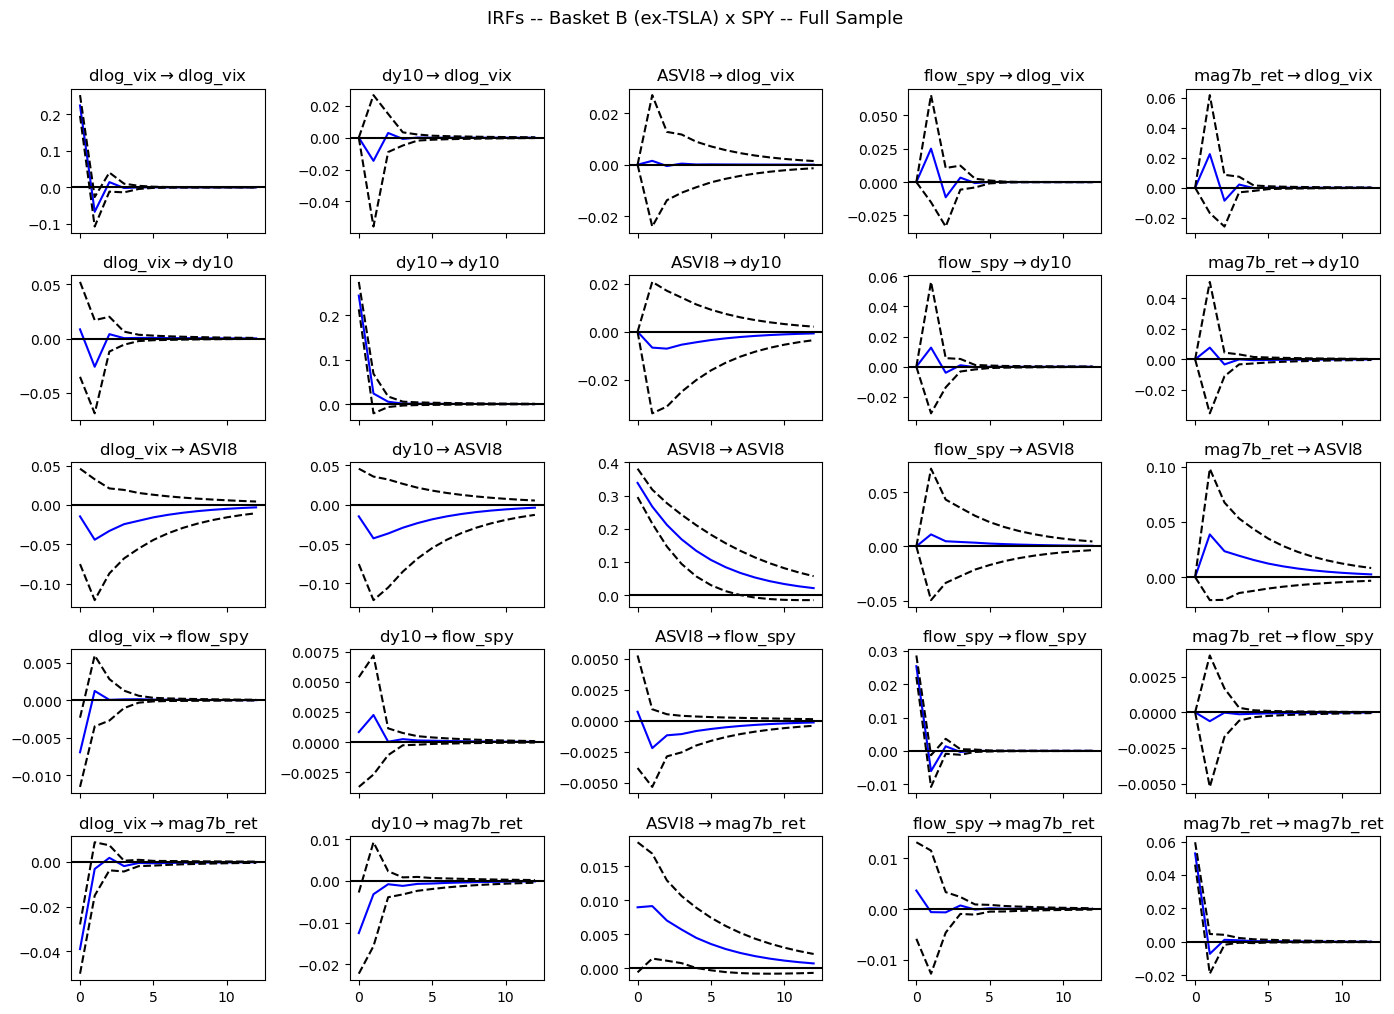

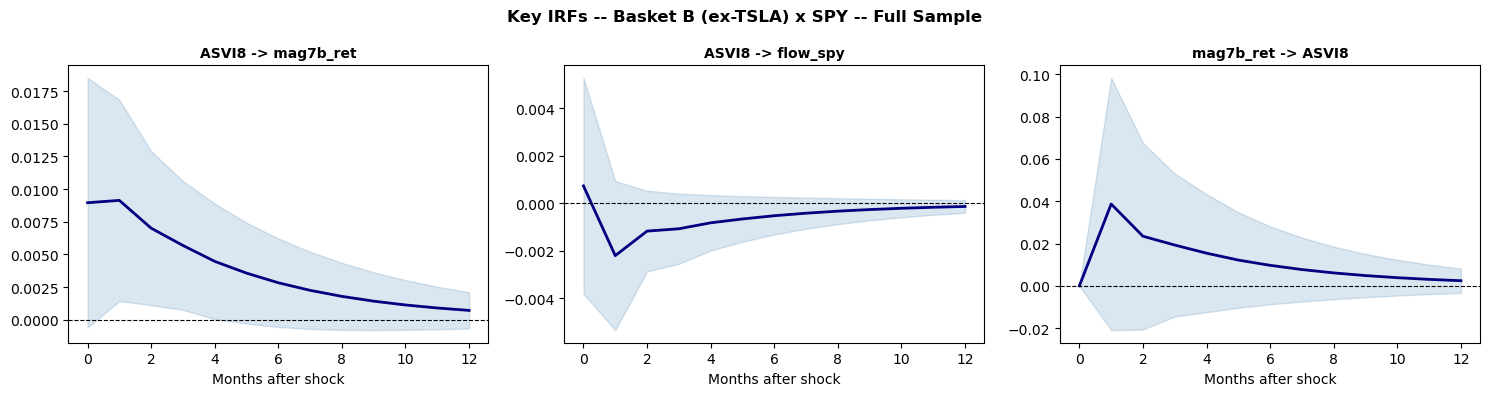

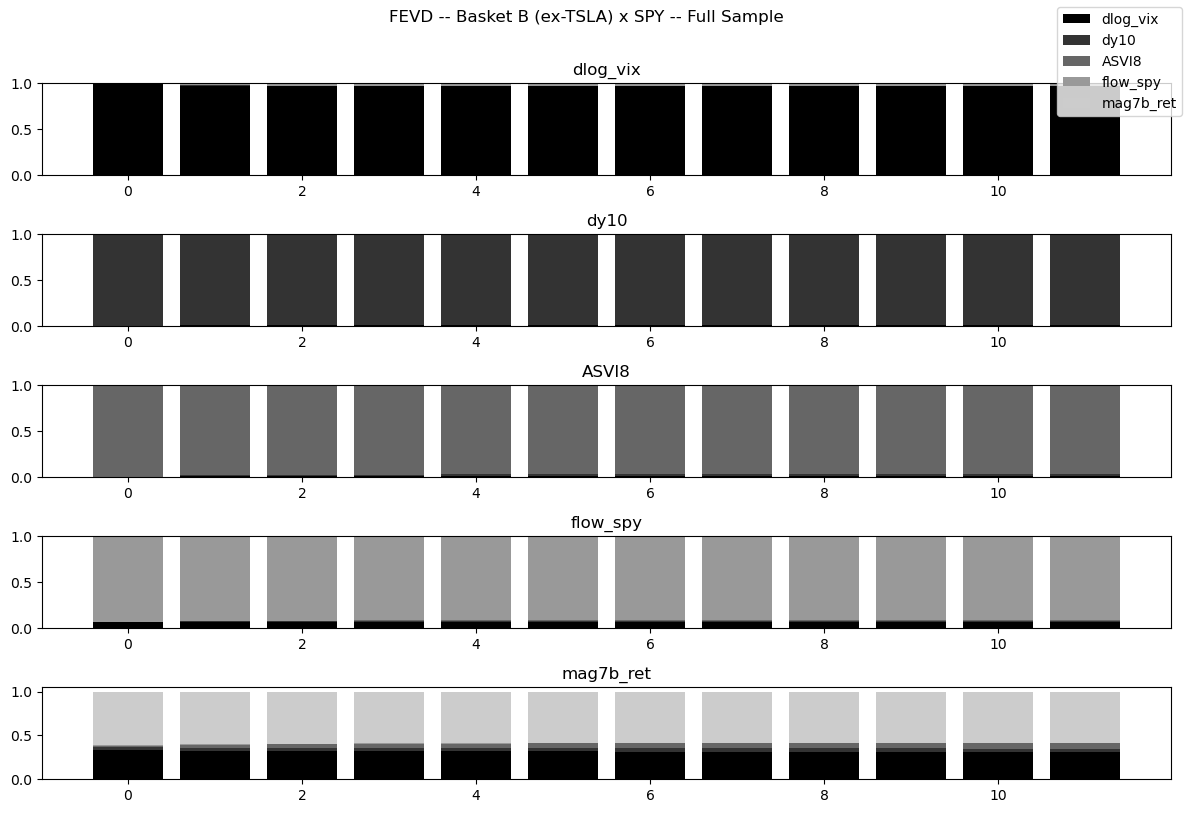


FEVD -- mag7b_ret:
Variable             t=1       t=6      t=12
--------------------------------------------
dlog_vix          33.4%    31.8%    31.6%
dy10               3.4%     3.5%     3.5%
ASVI8              1.8%     5.7%     6.1%
flow_spy           0.3%     0.3%     0.3%
mag7b_ret         61.2%    58.7%    58.5%


In [6]:
results_b_spy = run_var_basket(
    var_name   = "Basket B (ex-TSLA) x SPY -- Full Sample",
    flow_col   = "flow_spy",
    basket_col = "mag7b_ret",
    data       = var_df,
)


  Basket B (ex-TSLA) x RSP -- Full Sample  |  N=121
  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_rsp', 'mag7b_ret']

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -19.52      -19.40   3.334e-09      -19.47
1     -20.67*     -19.96*  1.054e-09*     -20.38*
2      -20.62      -19.32   1.115e-09      -20.09
3      -20.45      -18.56   1.330e-09      -19.68
4      -20.35      -17.87   1.484e-09      -19.34
-------------------------------------------------
BIC -> 1  |  AIC -> 1  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:43:58
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -20.0080
Nobs:                     120.000    HQIC:         

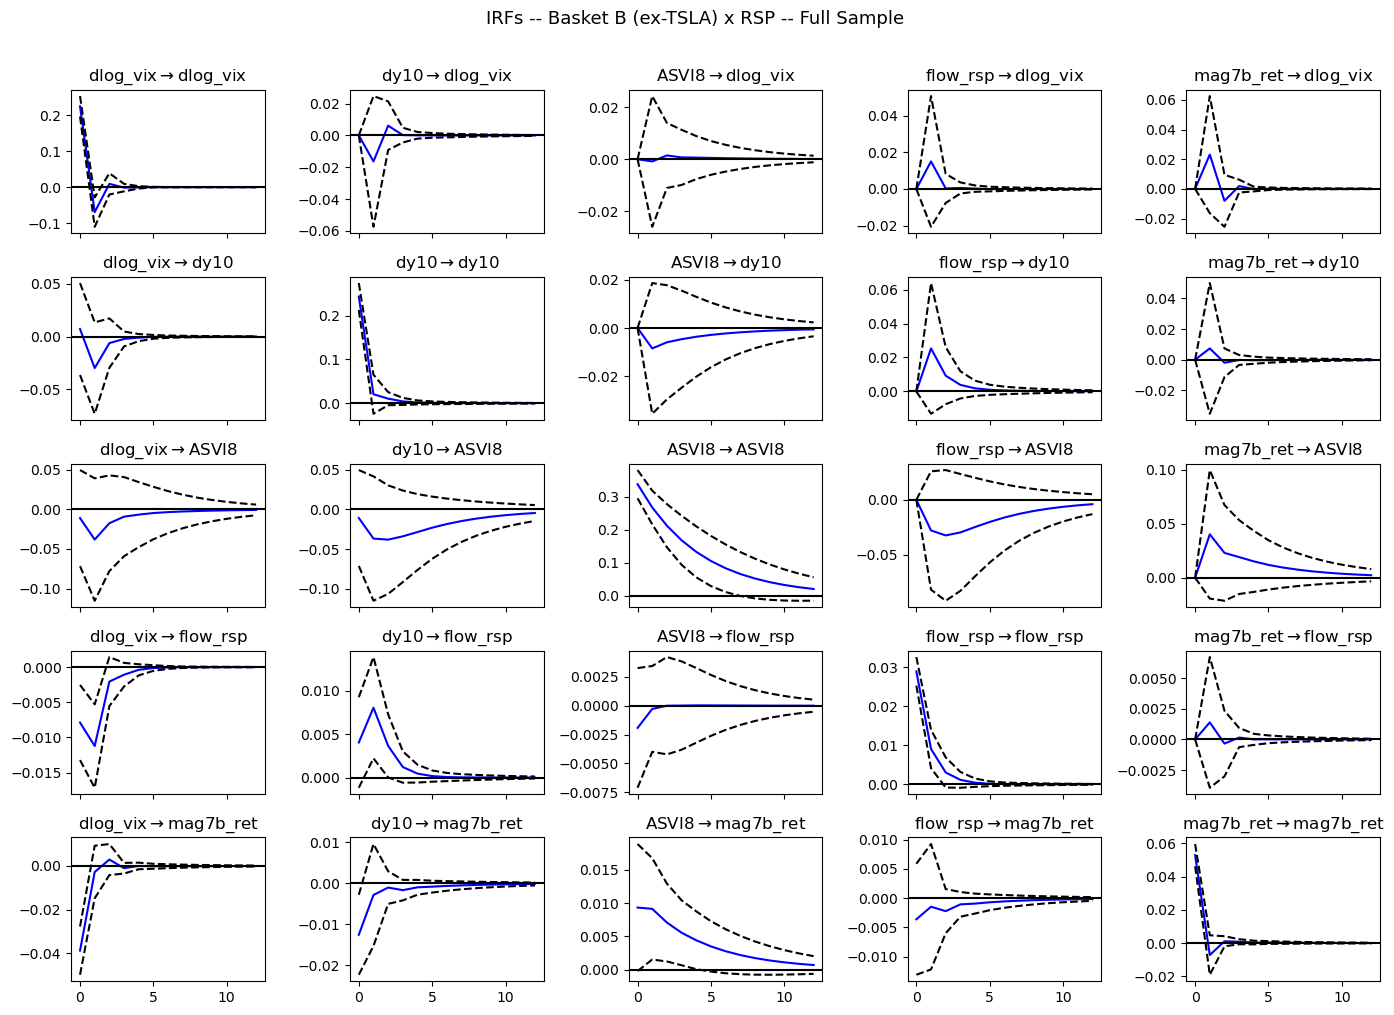

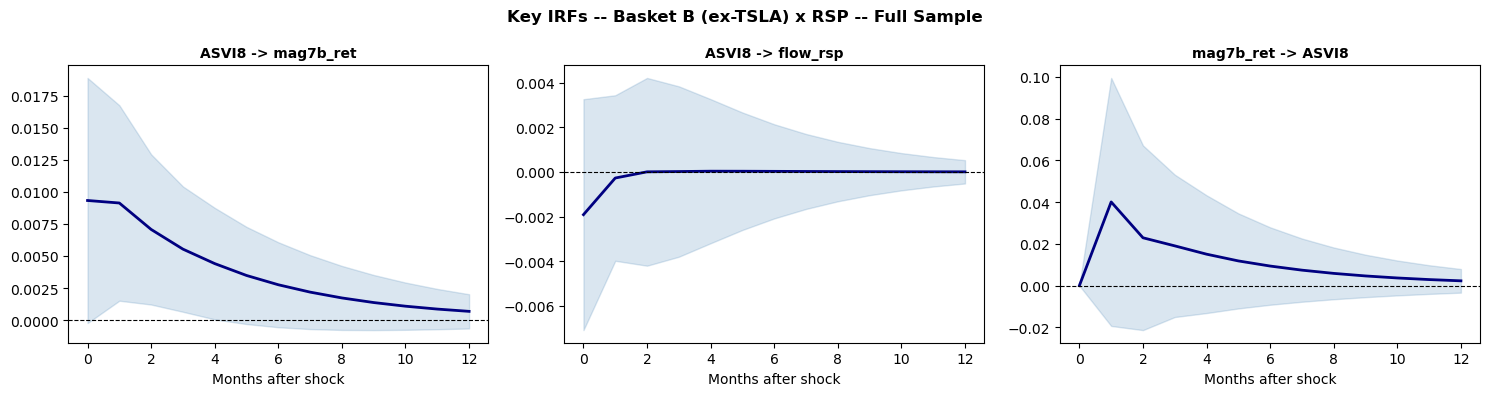

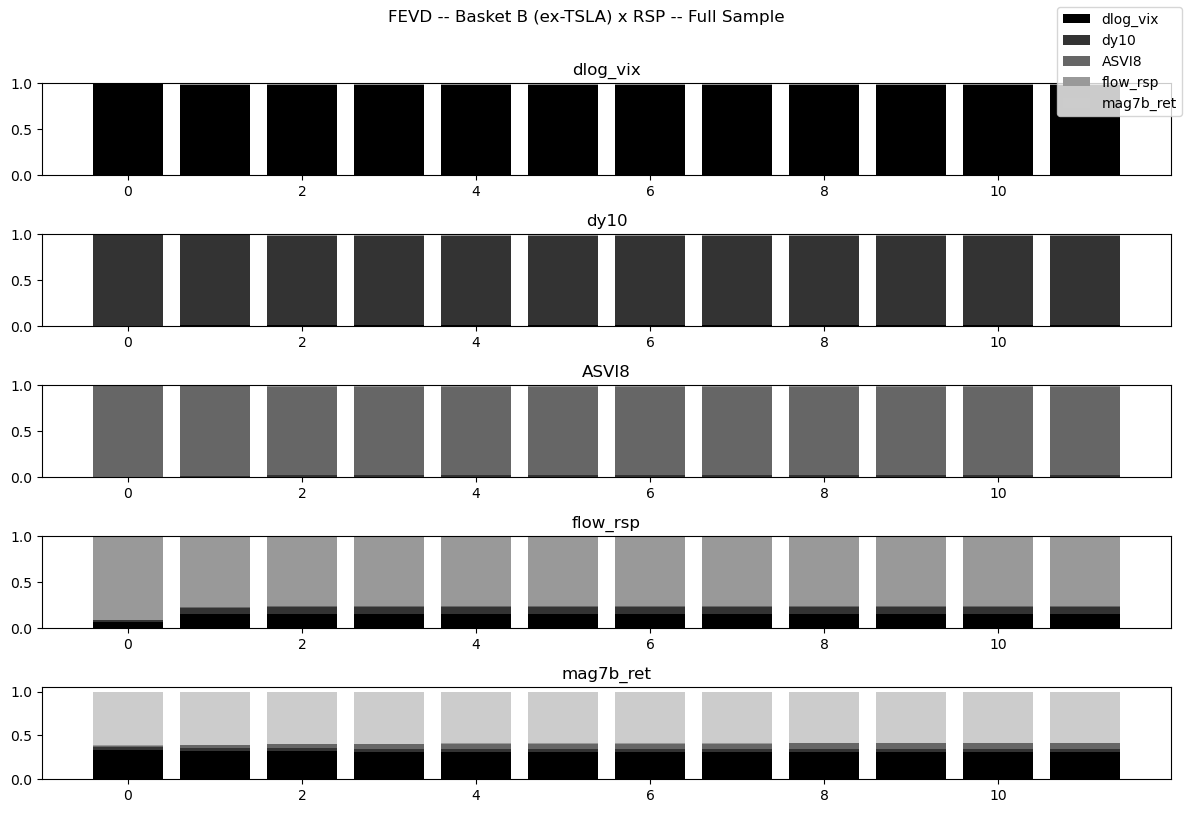


FEVD -- mag7b_ret:
Variable             t=1       t=6      t=12
--------------------------------------------
dlog_vix          32.9%    31.3%    31.2%
dy10               3.5%     3.5%     3.5%
ASVI8              1.9%     5.8%     6.2%
flow_rsp           0.3%     0.5%     0.5%
mag7b_ret         61.4%    58.9%    58.6%


In [7]:
results_b_rsp = run_var_basket(
    var_name   = "Basket B (ex-TSLA) x RSP -- Full Sample",
    flow_col   = "flow_rsp",
    basket_col = "mag7b_ret",
    data       = var_df,
)


  Basket B (ex-TSLA) x VOO -- Full Sample  |  N=121
  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_voo', 'mag7b_ret']

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -20.96      -20.84   7.921e-10      -20.91
1     -21.96*     -21.25*  2.918e-10*     -21.67*
2      -21.95      -20.66   2.928e-10      -21.43
3      -21.87      -19.98   3.200e-10      -21.10
4      -21.70      -19.22   3.843e-10      -20.69
-------------------------------------------------
BIC -> 1  |  AIC -> 1  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:43:59
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -21.2889
Nobs:                     120.000    HQIC:         

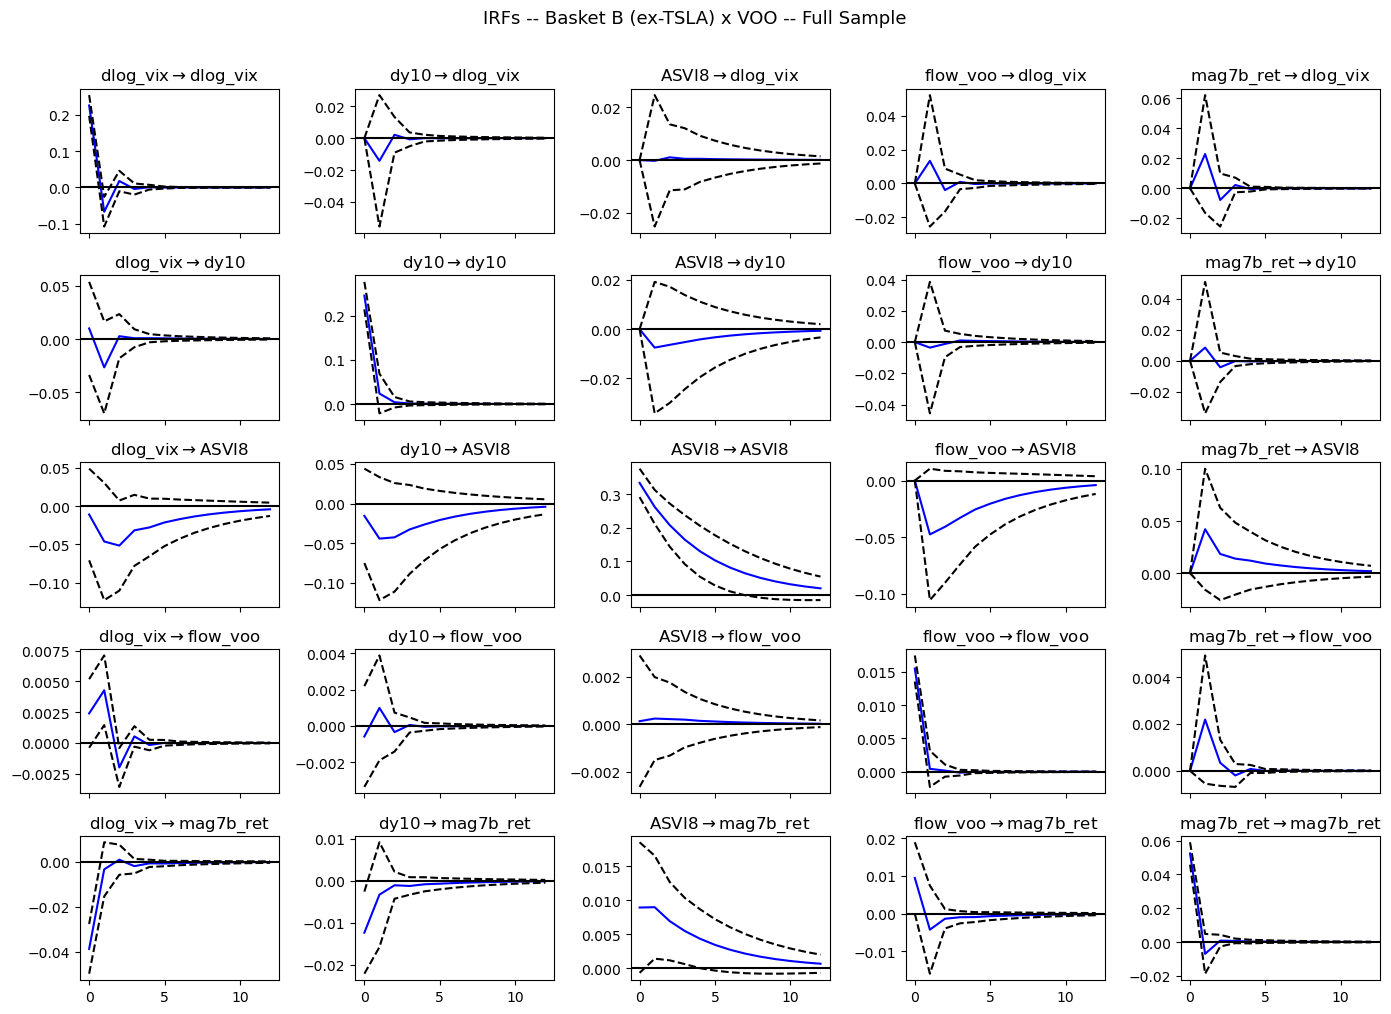

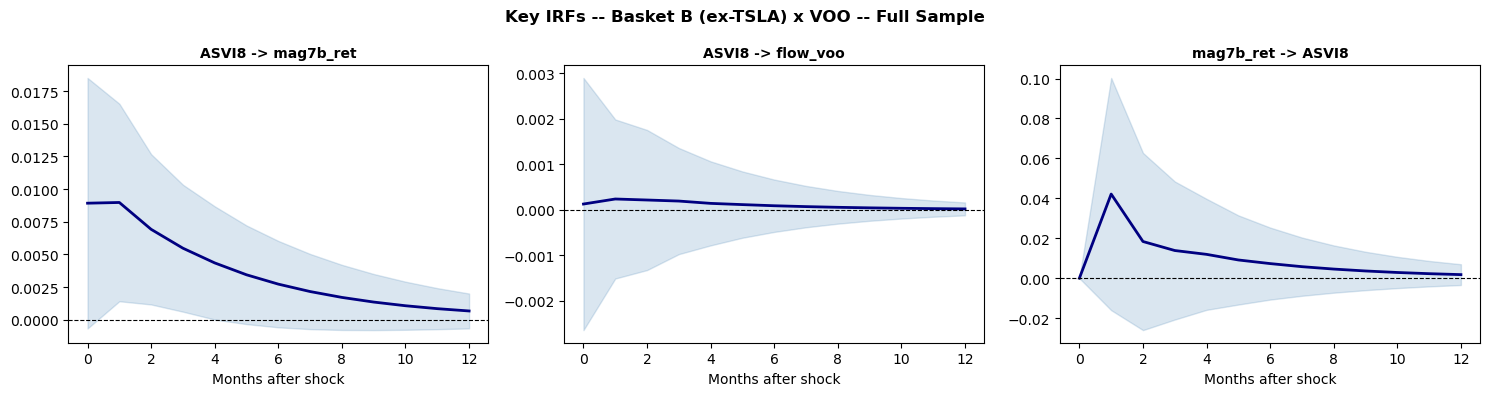

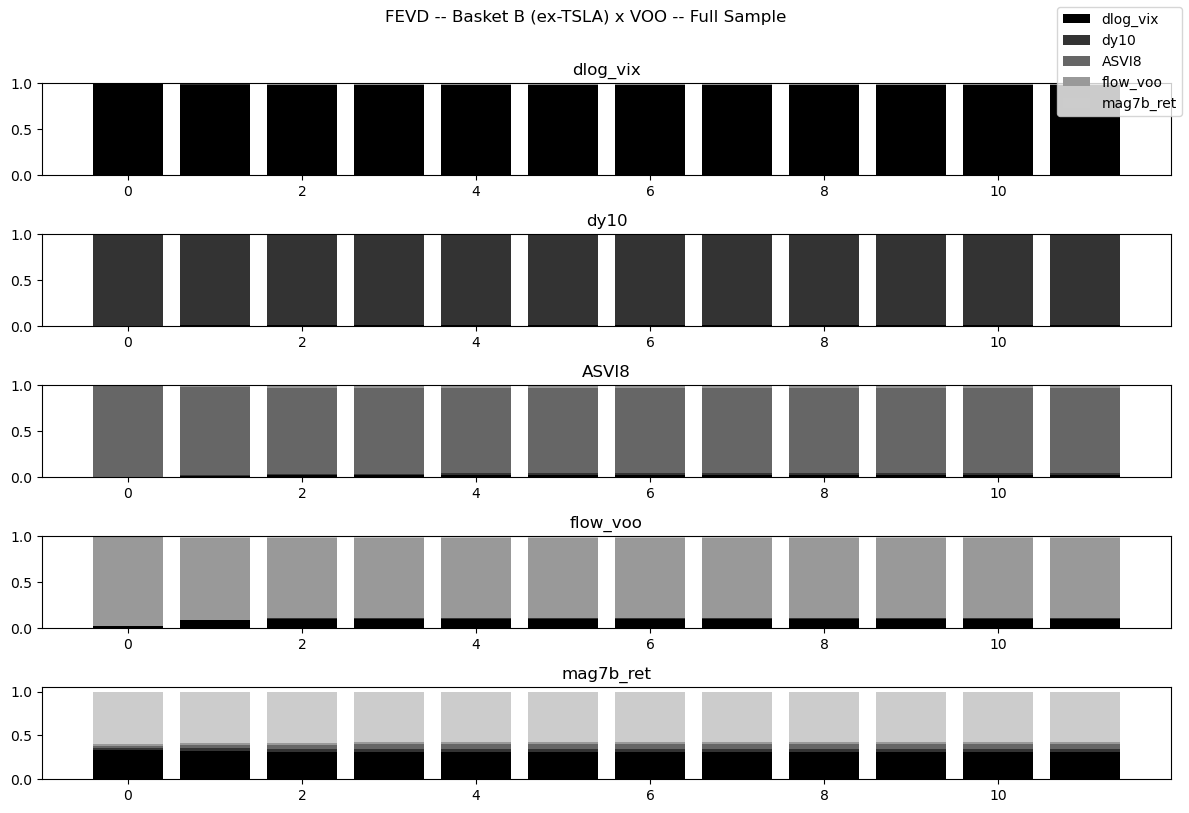


FEVD -- mag7b_ret:
Variable             t=1       t=6      t=12
--------------------------------------------
dlog_vix          32.9%    31.3%    31.1%
dy10               3.4%     3.5%     3.5%
ASVI8              1.7%     5.5%     5.9%
flow_voo           2.0%     2.3%     2.3%
mag7b_ret         60.1%    57.5%    57.2%


In [8]:
results_b_voo = run_var_basket(
    var_name   = "Basket B (ex-TSLA) x VOO -- Full Sample",
    flow_col   = "flow_voo",
    basket_col = "mag7b_ret",
    data       = var_df,
)


  Basket C (AI-pure 4) x SPY -- Full Sample  |  N=121
  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_spy', 'mag7c_ret']

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -19.88      -19.76   2.319e-09      -19.83
1     -20.79*     -20.08*  9.405e-10*     -20.50*
2      -20.77      -19.48   9.532e-10      -20.25
3      -20.60      -18.71   1.144e-09      -19.83
4      -20.49      -18.01   1.284e-09      -19.49
-------------------------------------------------
BIC -> 1  |  AIC -> 1  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:44:01
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -20.1576
Nobs:                     120.000    HQIC:       

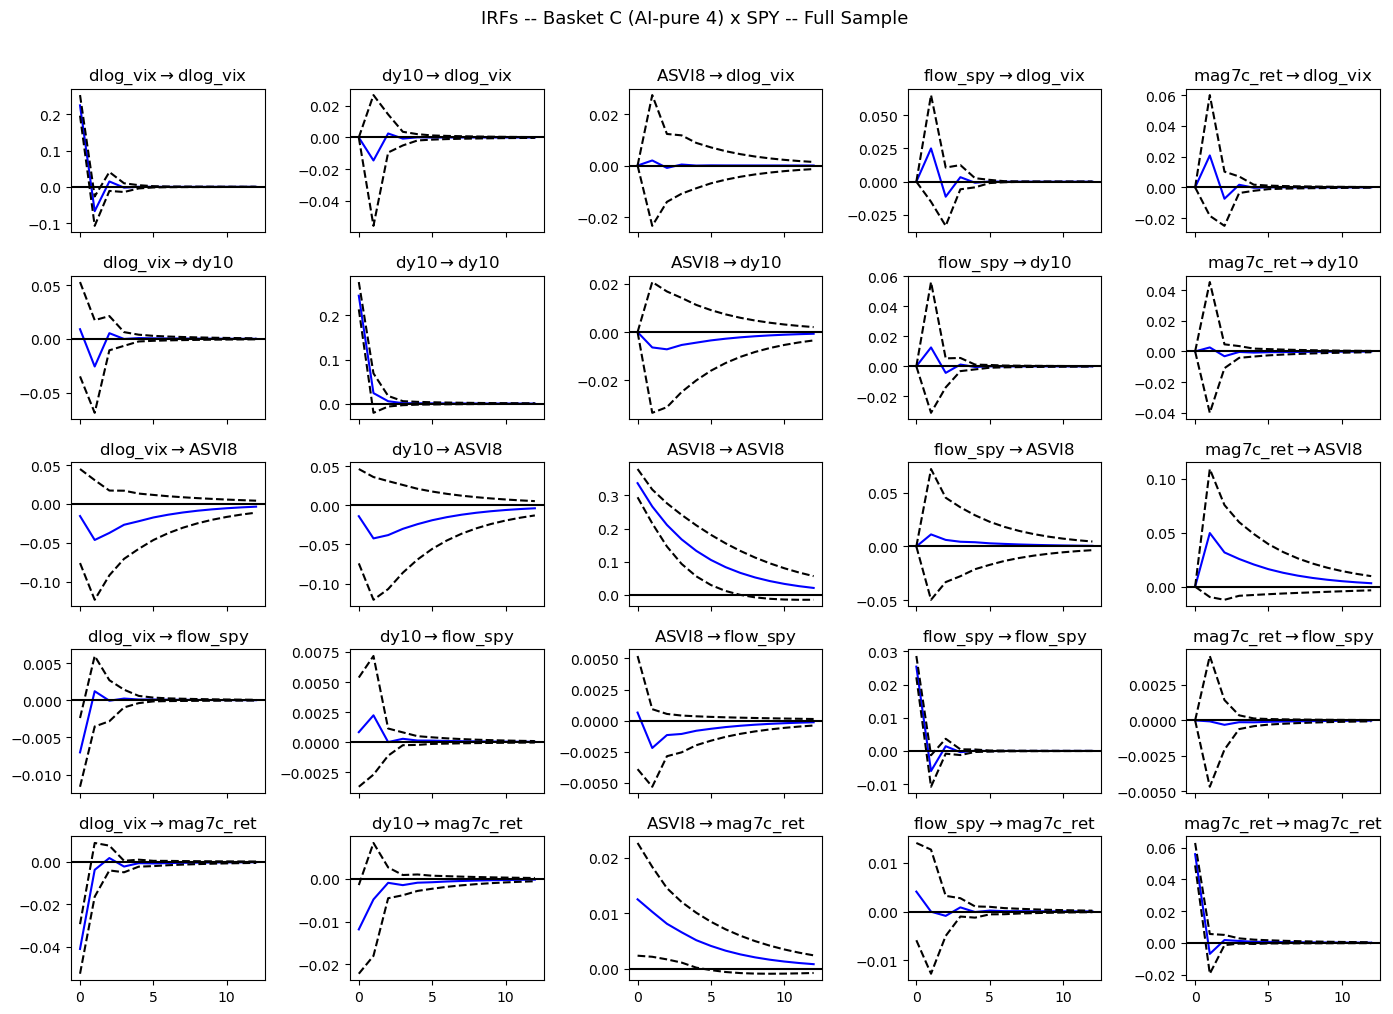

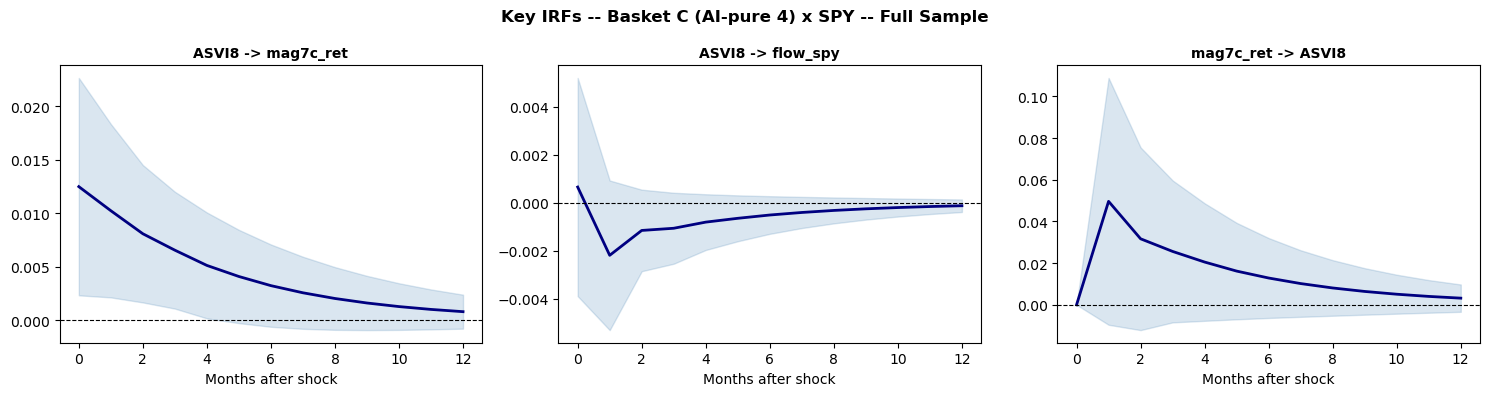

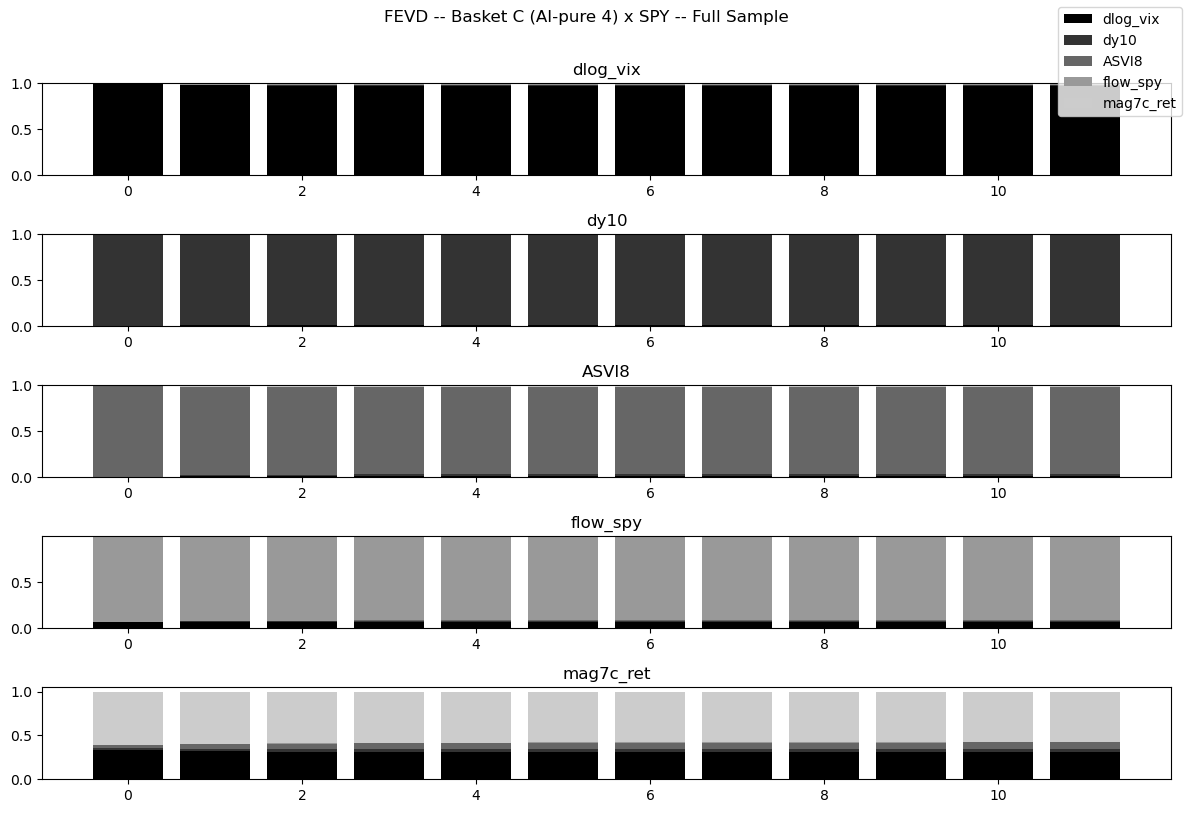


FEVD -- mag7c_ret:
Variable             t=1       t=6      t=12
--------------------------------------------
dlog_vix          32.9%    31.2%    31.0%
dy10               2.7%     3.0%     3.0%
ASVI8              3.0%     7.5%     8.0%
flow_spy           0.3%     0.3%     0.3%
mag7c_ret         61.0%    57.9%    57.6%


In [9]:
results_c_spy = run_var_basket(
    var_name   = "Basket C (AI-pure 4) x SPY -- Full Sample",
    flow_col   = "flow_spy",
    basket_col = "mag7c_ret",
    data       = var_df,
)


  Basket C (AI-pure 4) x RSP -- Full Sample  |  N=121
  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_rsp', 'mag7c_ret']

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -19.39      -19.27   3.782e-09      -19.34
1     -20.56*     -19.85*  1.175e-09*     -20.27*
2      -20.48      -19.18   1.283e-09      -19.95
3      -20.29      -18.40   1.559e-09      -19.52
4      -20.22      -17.75   1.680e-09      -19.22
-------------------------------------------------
BIC -> 1  |  AIC -> 1  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:44:02
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -19.9113
Nobs:                     120.000    HQIC:       

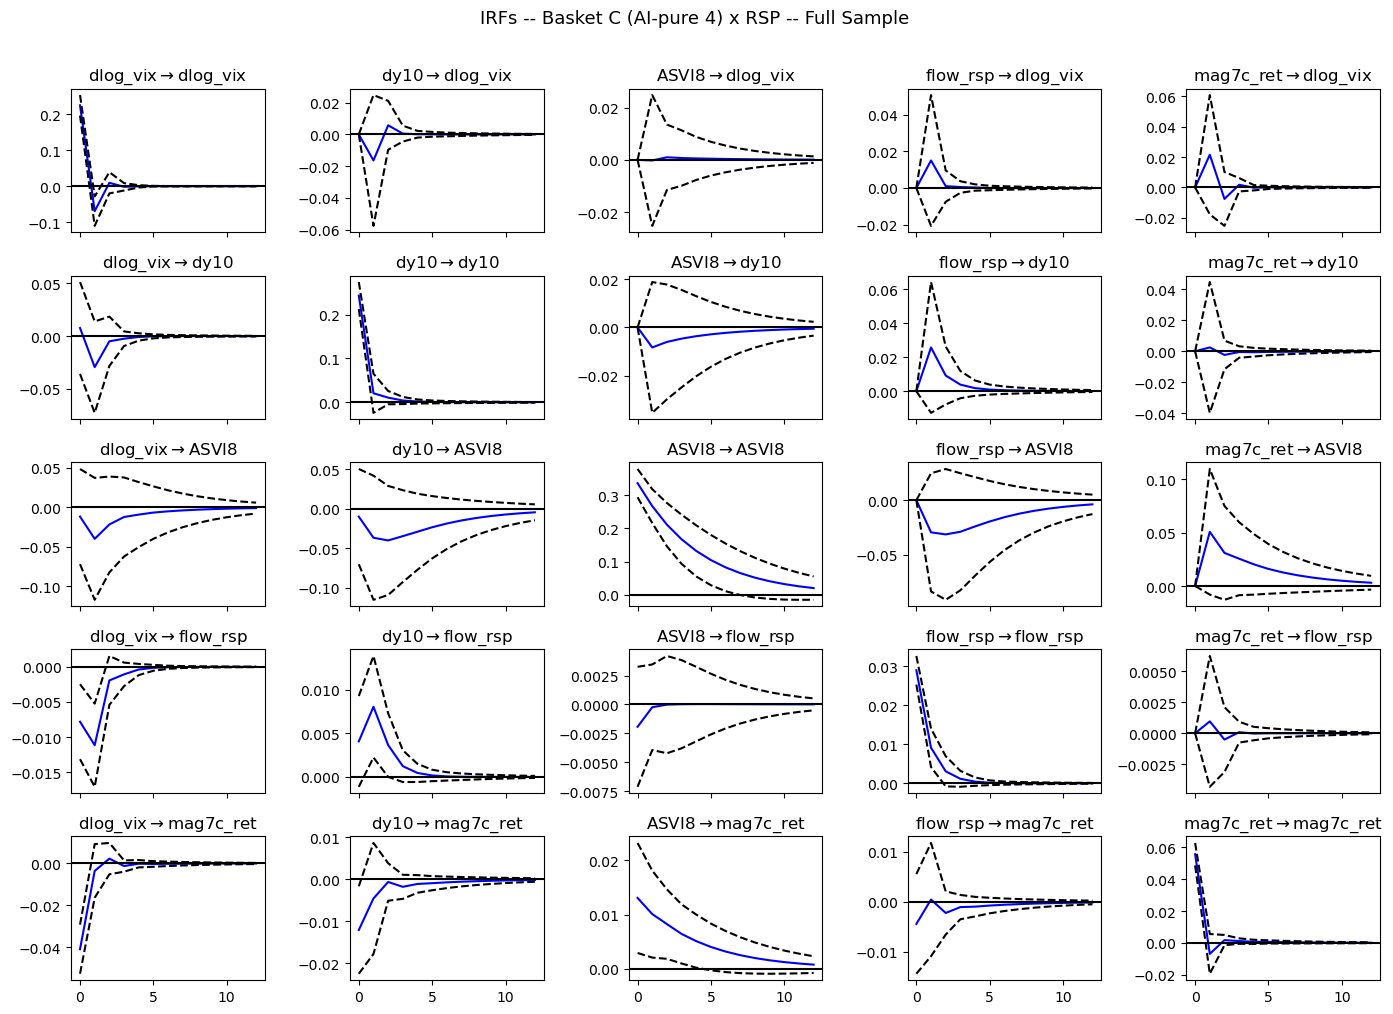

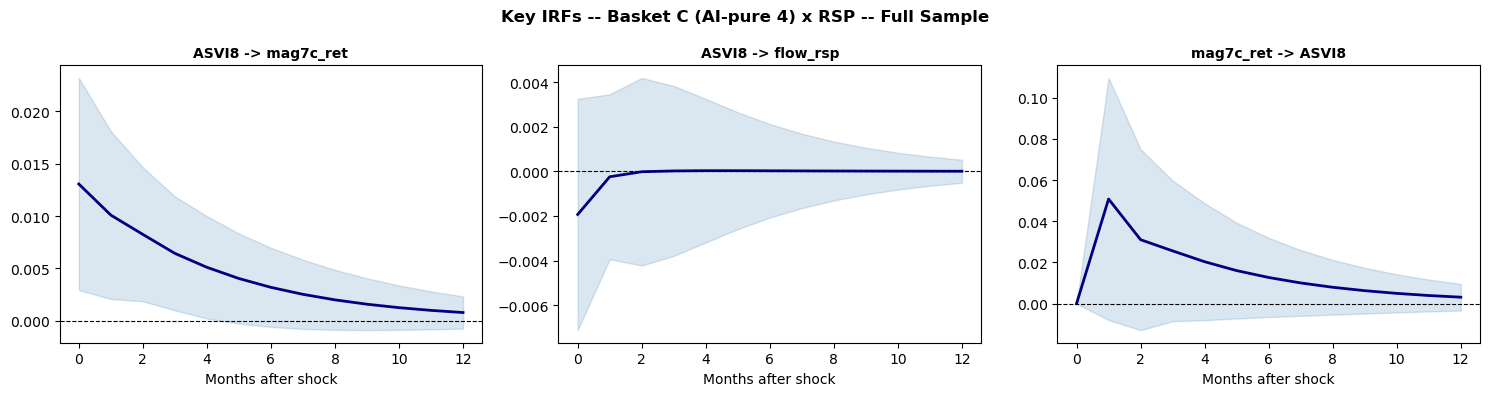

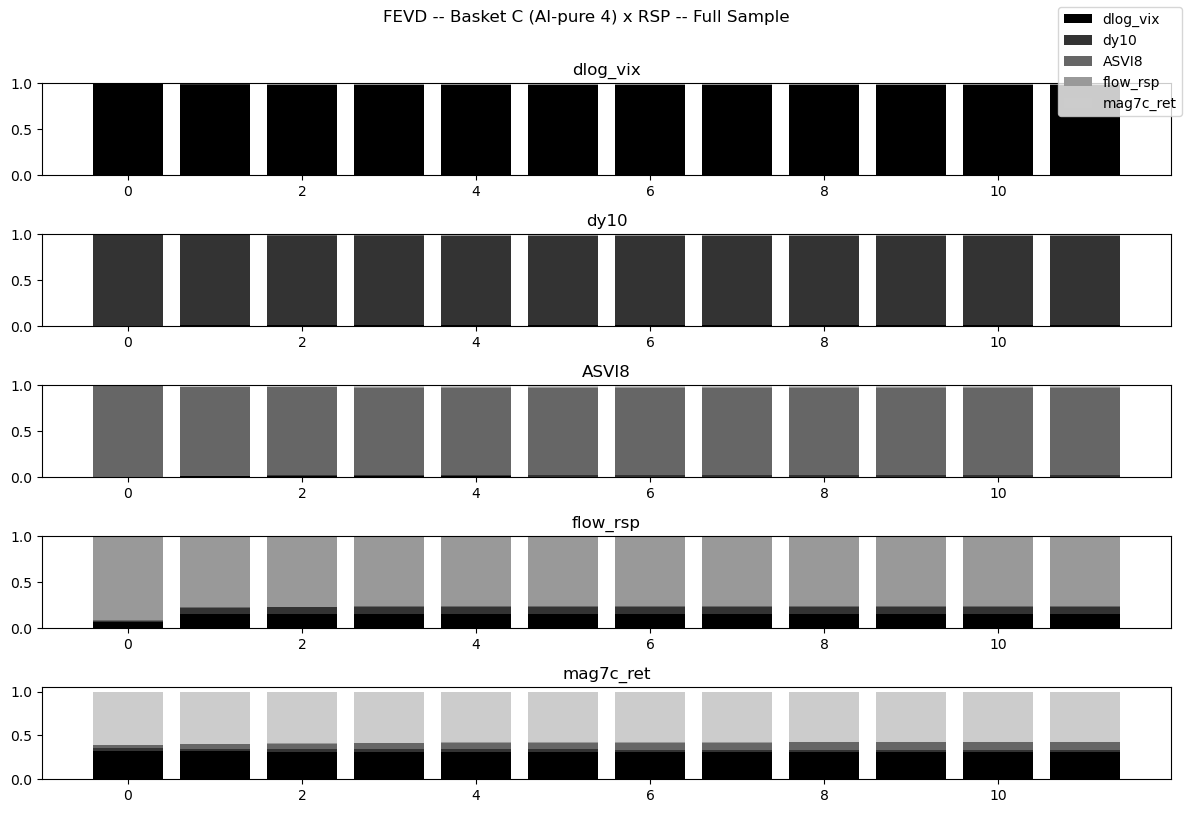


FEVD -- mag7c_ret:
Variable             t=1       t=6      t=12
--------------------------------------------
dlog_vix          32.7%    30.9%    30.8%
dy10               2.8%     3.1%     3.1%
ASVI8              3.3%     7.7%     8.2%
flow_rsp           0.4%     0.5%     0.5%
mag7c_ret         60.7%    57.7%    57.4%


In [10]:
results_c_rsp = run_var_basket(
    var_name   = "Basket C (AI-pure 4) x RSP -- Full Sample",
    flow_col   = "flow_rsp",
    basket_col = "mag7c_ret",
    data       = var_df,
)


  Basket C (AI-pure 4) x VOO -- Full Sample  |  N=121
  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_voo', 'mag7c_ret']

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -20.83      -20.71   9.009e-10      -20.78
1     -21.84*     -21.13*  3.273e-10*     -21.55*
2      -21.81      -20.51   3.381e-10      -21.28
3      -21.70      -19.81   3.796e-10      -20.93
4      -21.55      -19.07   4.458e-10      -20.54
-------------------------------------------------
BIC -> 1  |  AIC -> 1  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:44:03
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -21.1895
Nobs:                     120.000    HQIC:       

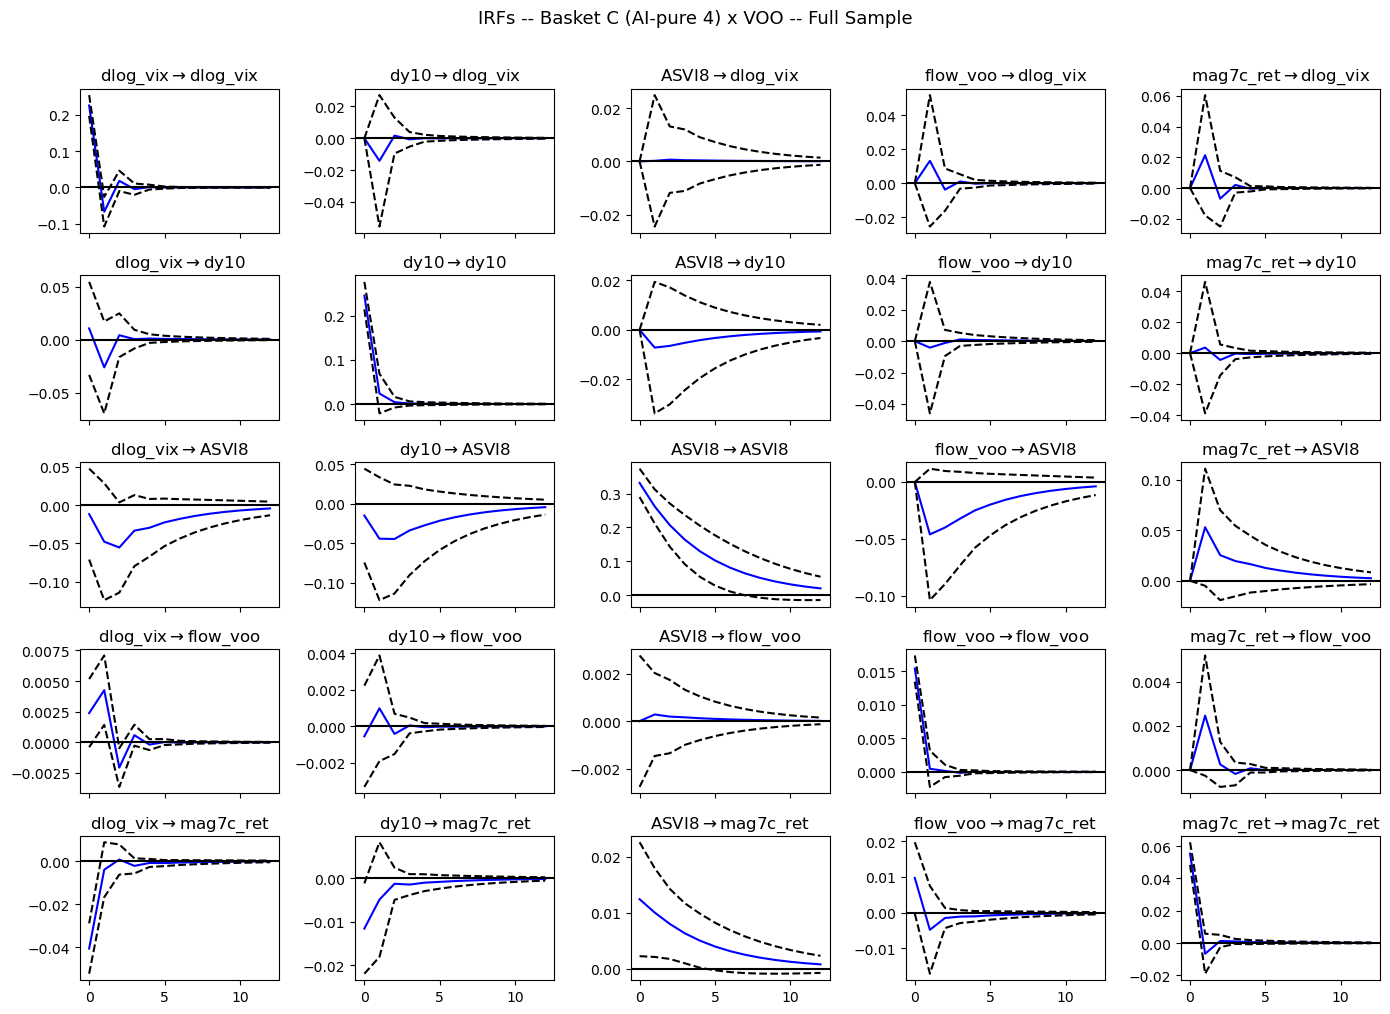

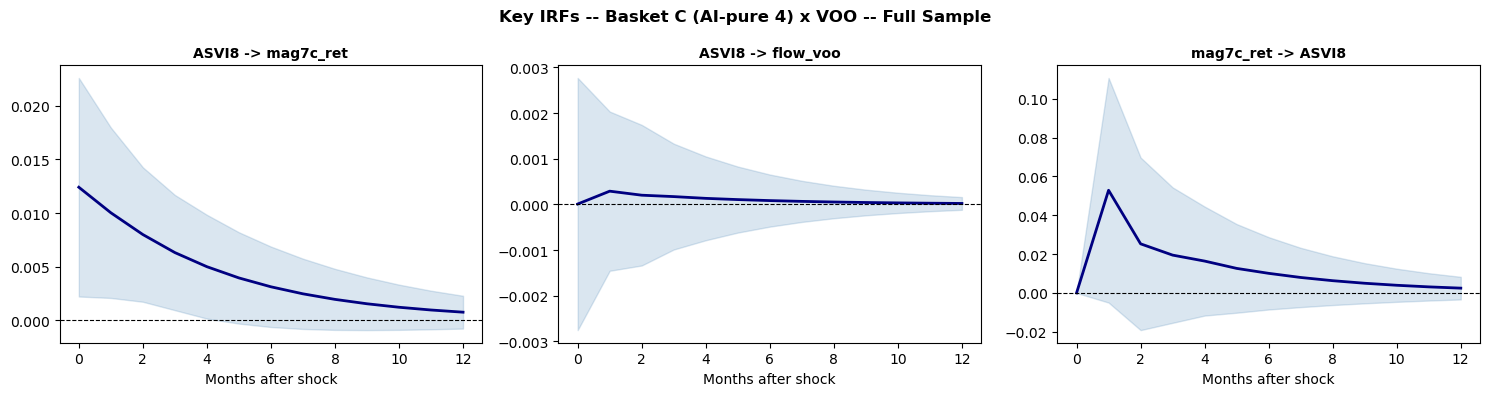

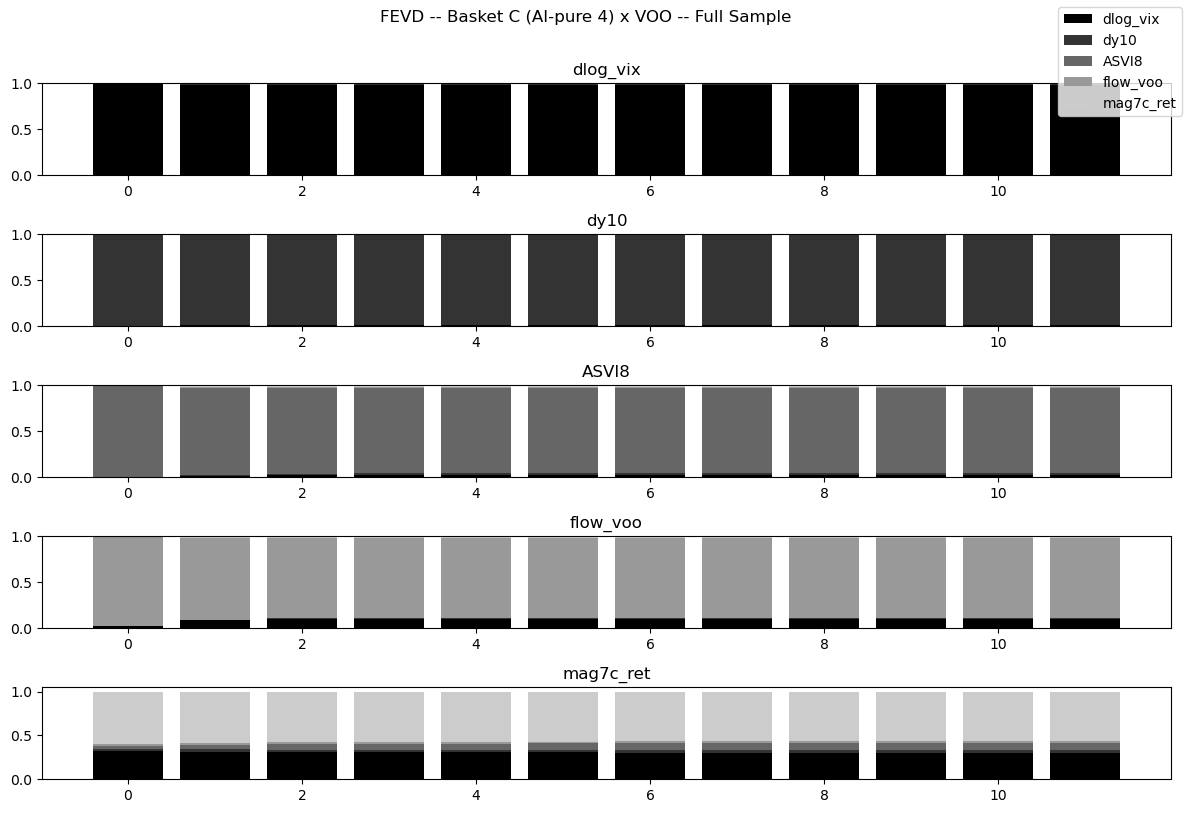


FEVD -- mag7c_ret:
Variable             t=1       t=6      t=12
--------------------------------------------
dlog_vix          32.4%    30.6%    30.4%
dy10               2.6%     3.0%     3.0%
ASVI8              3.0%     7.3%     7.7%
flow_voo           1.9%     2.2%     2.2%
mag7c_ret         60.1%    56.9%    56.6%


In [11]:
results_c_voo = run_var_basket(
    var_name   = "Basket C (AI-pure 4) x VOO -- Full Sample",
    flow_col   = "flow_voo",
    basket_col = "mag7c_ret",
    data       = var_df,
)


  Basket B (ex-TSLA) x SPY -- 2021+  |  N=61
  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_spy', 'mag7b_ret']

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -19.80      -19.62   2.519e-09      -19.73
1      -20.86     -19.79*  8.731e-10*     -20.45*
2      -20.83      -18.85   9.255e-10      -20.06
3      -20.67      -17.80   1.142e-09      -19.55
4     -20.88*      -17.11   1.029e-09      -19.41
-------------------------------------------------
BIC -> 1  |  AIC -> 4  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:44:04
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -19.7313
Nobs:                     60.0000    HQIC:                

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


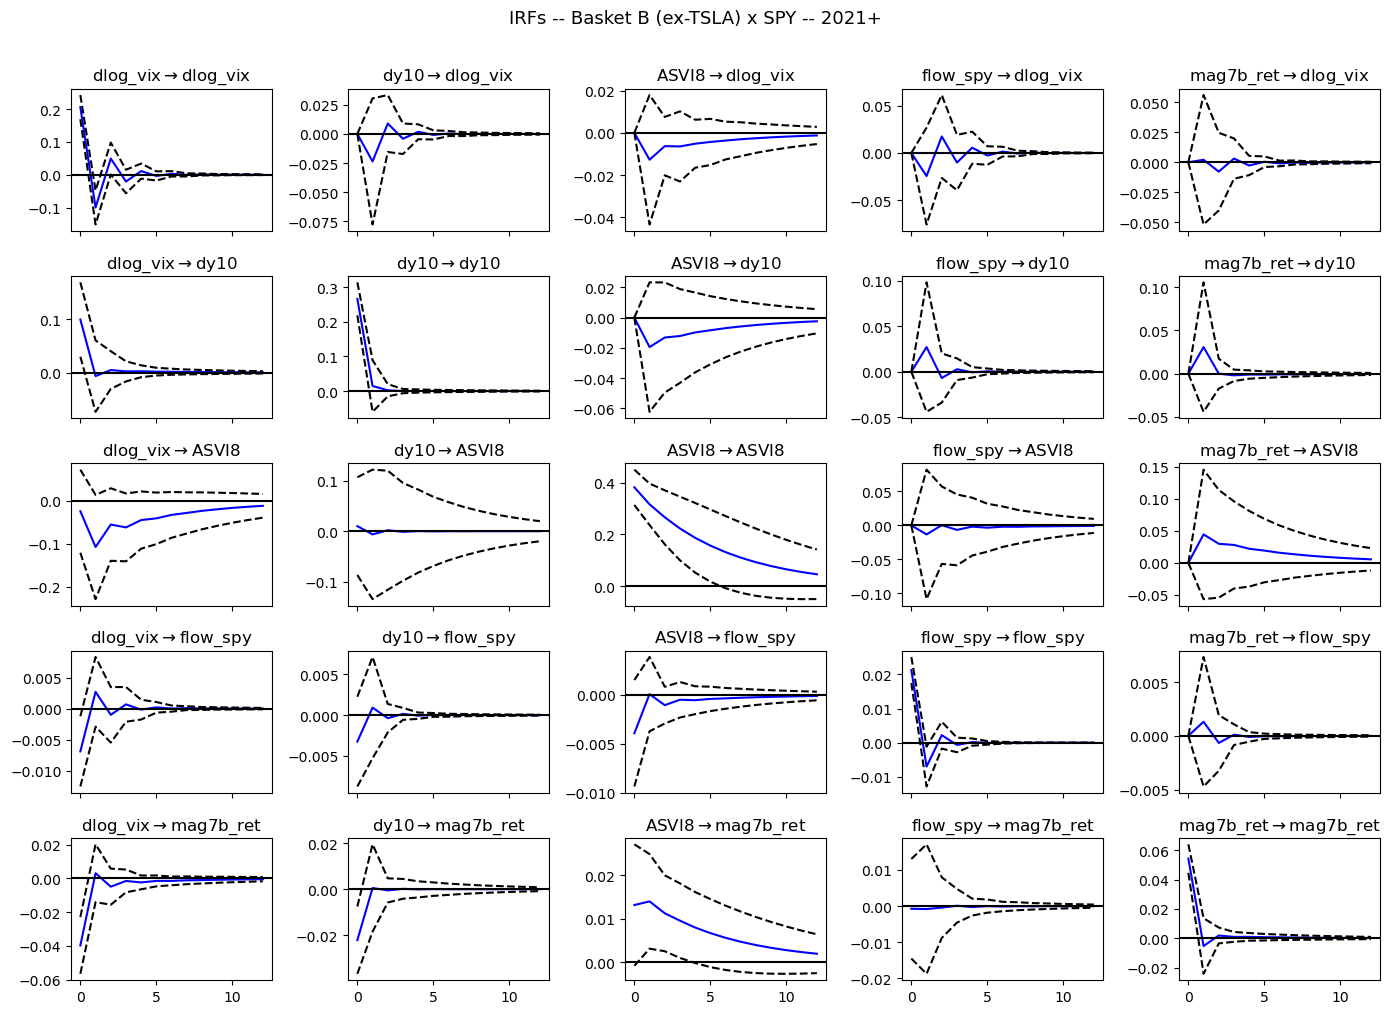

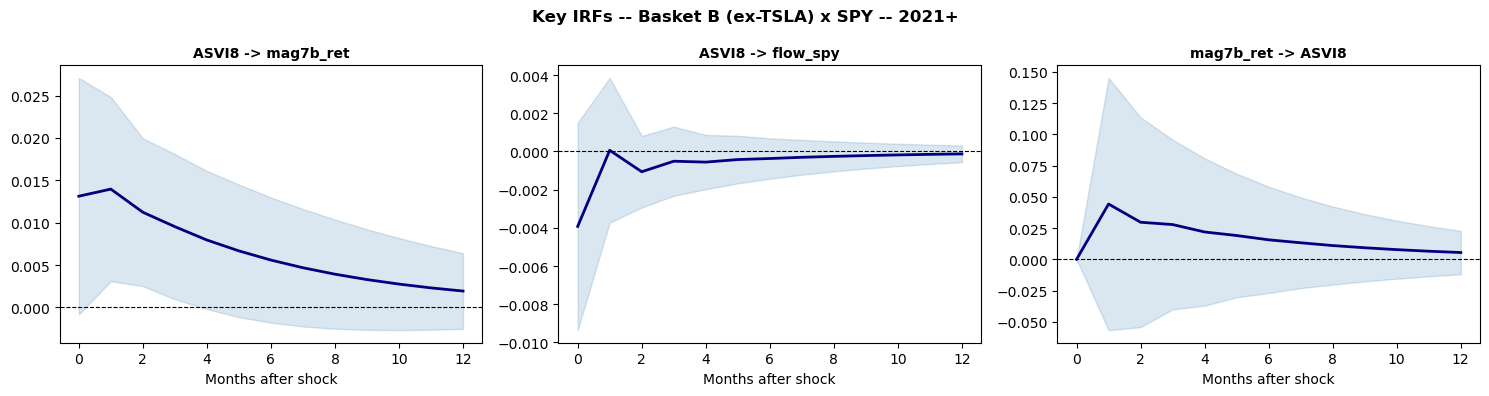

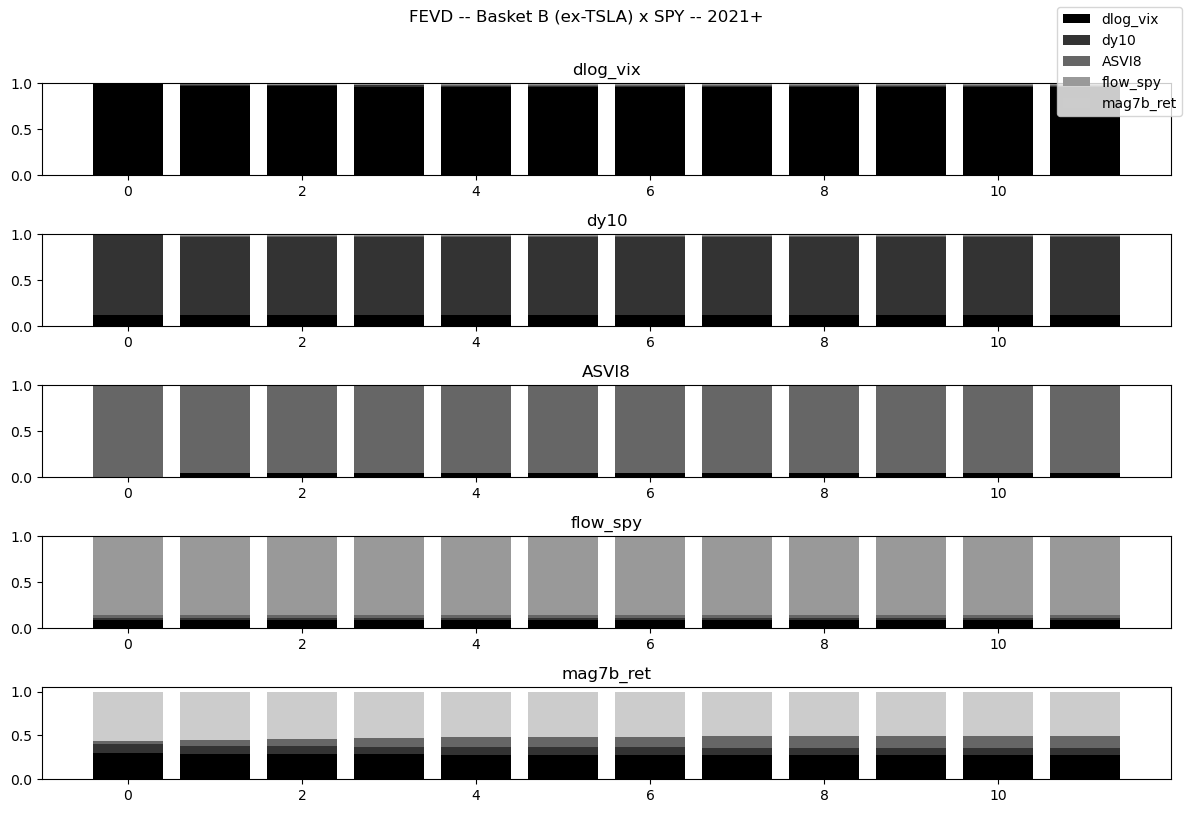


FEVD -- mag7b_ret:
Variable             t=1       t=6      t=12
--------------------------------------------
dlog_vix          30.3%    28.0%    27.6%
dy10               9.5%     8.5%     8.4%
ASVI8              3.3%    11.9%    13.3%
flow_spy           0.0%     0.0%     0.0%
mag7b_ret         56.8%    51.5%    50.7%


In [12]:
results_b_spy_21 = run_var_basket(
    var_name   = "Basket B (ex-TSLA) x SPY -- 2021+",
    flow_col   = "flow_spy",
    basket_col = "mag7b_ret",
    data       = var_df_2021,
)


  Basket B (ex-TSLA) x RSP -- 2021+  |  N=61
  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_rsp', 'mag7b_ret']

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -19.02      -18.85   5.467e-09      -18.95
1     -20.18*     -19.10*  1.733e-09*     -19.76*
2      -20.01      -18.04   2.092e-09      -19.24
3      -19.90      -17.03   2.464e-09      -18.78
4      -20.01      -16.24   2.458e-09      -18.54
-------------------------------------------------
BIC -> 1  |  AIC -> 1  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:44:05
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -18.8836
Nobs:                     60.0000    HQIC:                

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


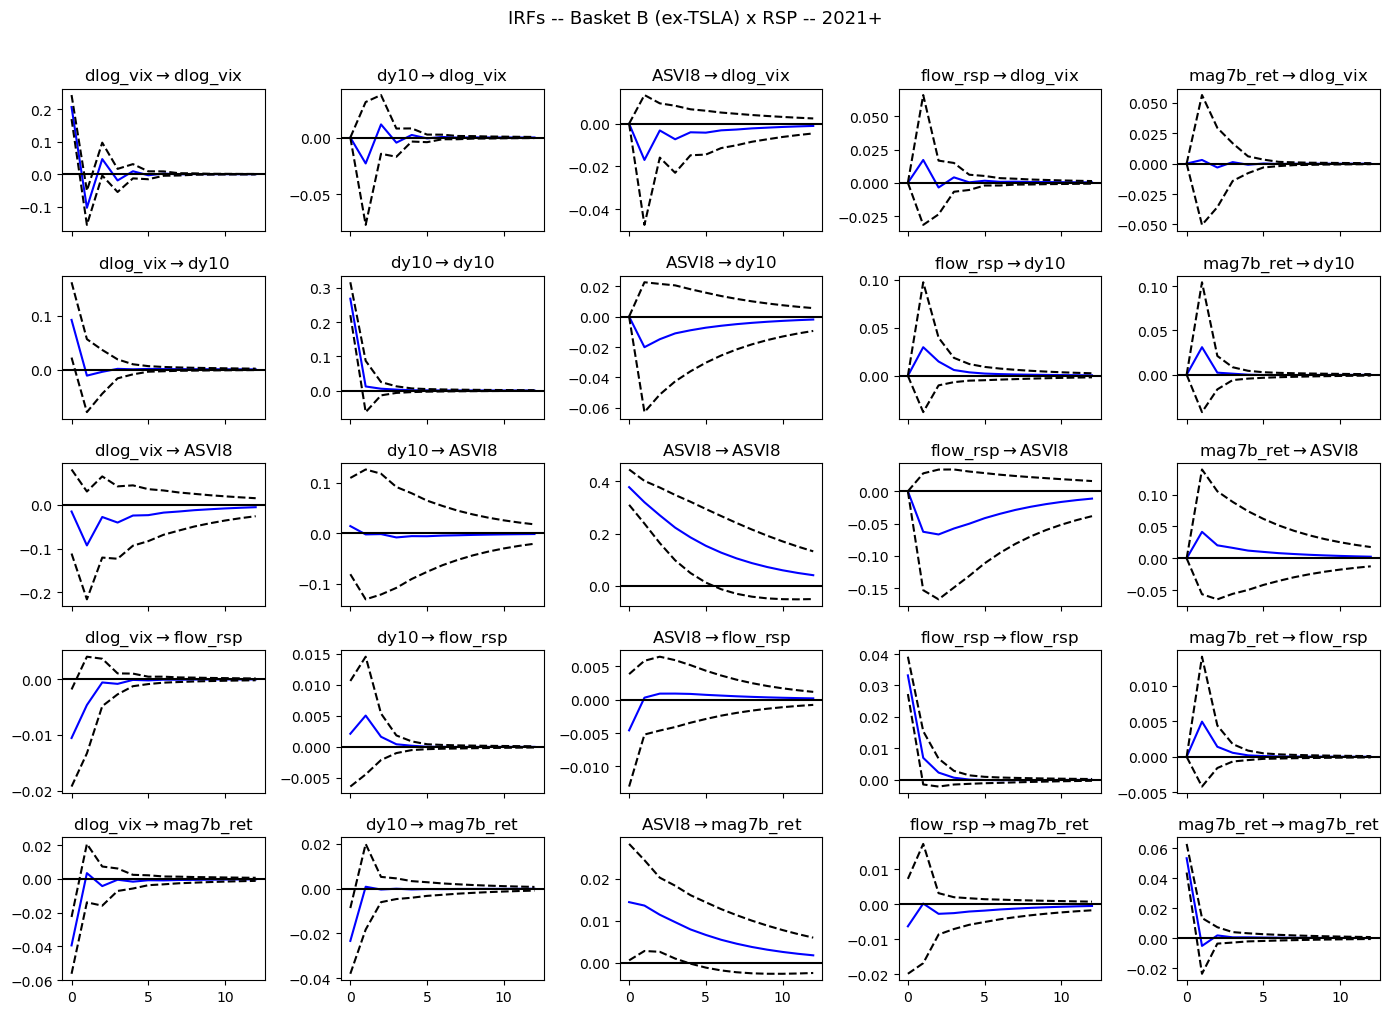

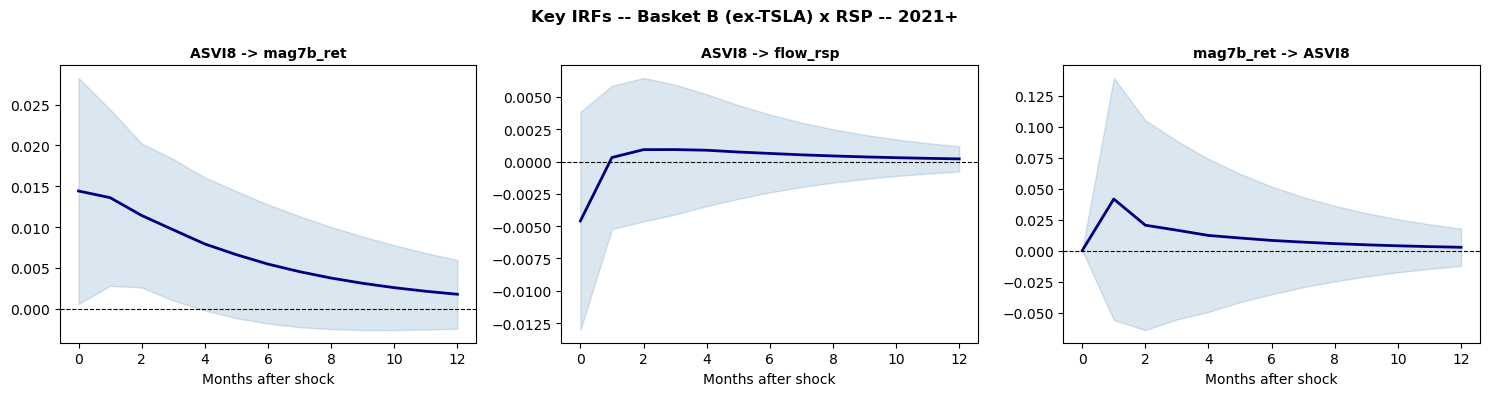

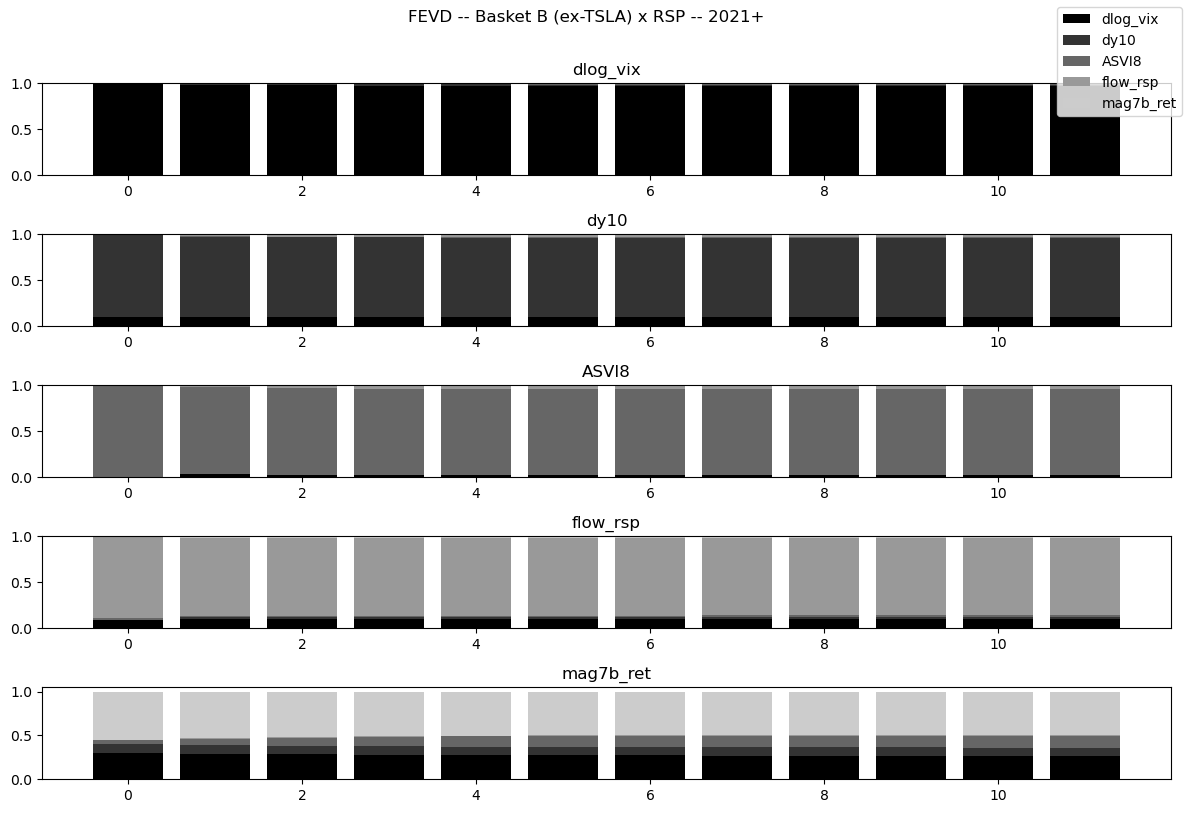


FEVD -- mag7b_ret:
Variable             t=1       t=6      t=12
--------------------------------------------
dlog_vix          29.9%    27.4%    26.9%
dy10              10.5%     9.4%     9.3%
ASVI8              4.0%    12.5%    13.7%
flow_rsp           0.8%     1.1%     1.1%
mag7b_ret         54.8%    49.7%    48.9%


In [13]:
results_b_rsp_21 = run_var_basket(
    var_name   = "Basket B (ex-TSLA) x RSP -- 2021+",
    flow_col   = "flow_rsp",
    basket_col = "mag7b_ret",
    data       = var_df_2021,
)


  Basket B (ex-TSLA) x VOO -- 2021+  |  N=61
  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_voo', 'mag7b_ret']

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -20.81      -20.63   9.179e-10      -20.74
1      -22.19     -21.11*   2.322e-10     -21.77*
2      -22.15      -20.18   2.452e-10      -21.39
3      -22.35      -19.49   2.116e-10      -21.24
4     -22.79*      -19.03  1.511e-10*      -21.33
-------------------------------------------------
BIC -> 1  |  AIC -> 4  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:44:07
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -21.0774
Nobs:                     60.0000    HQIC:                

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


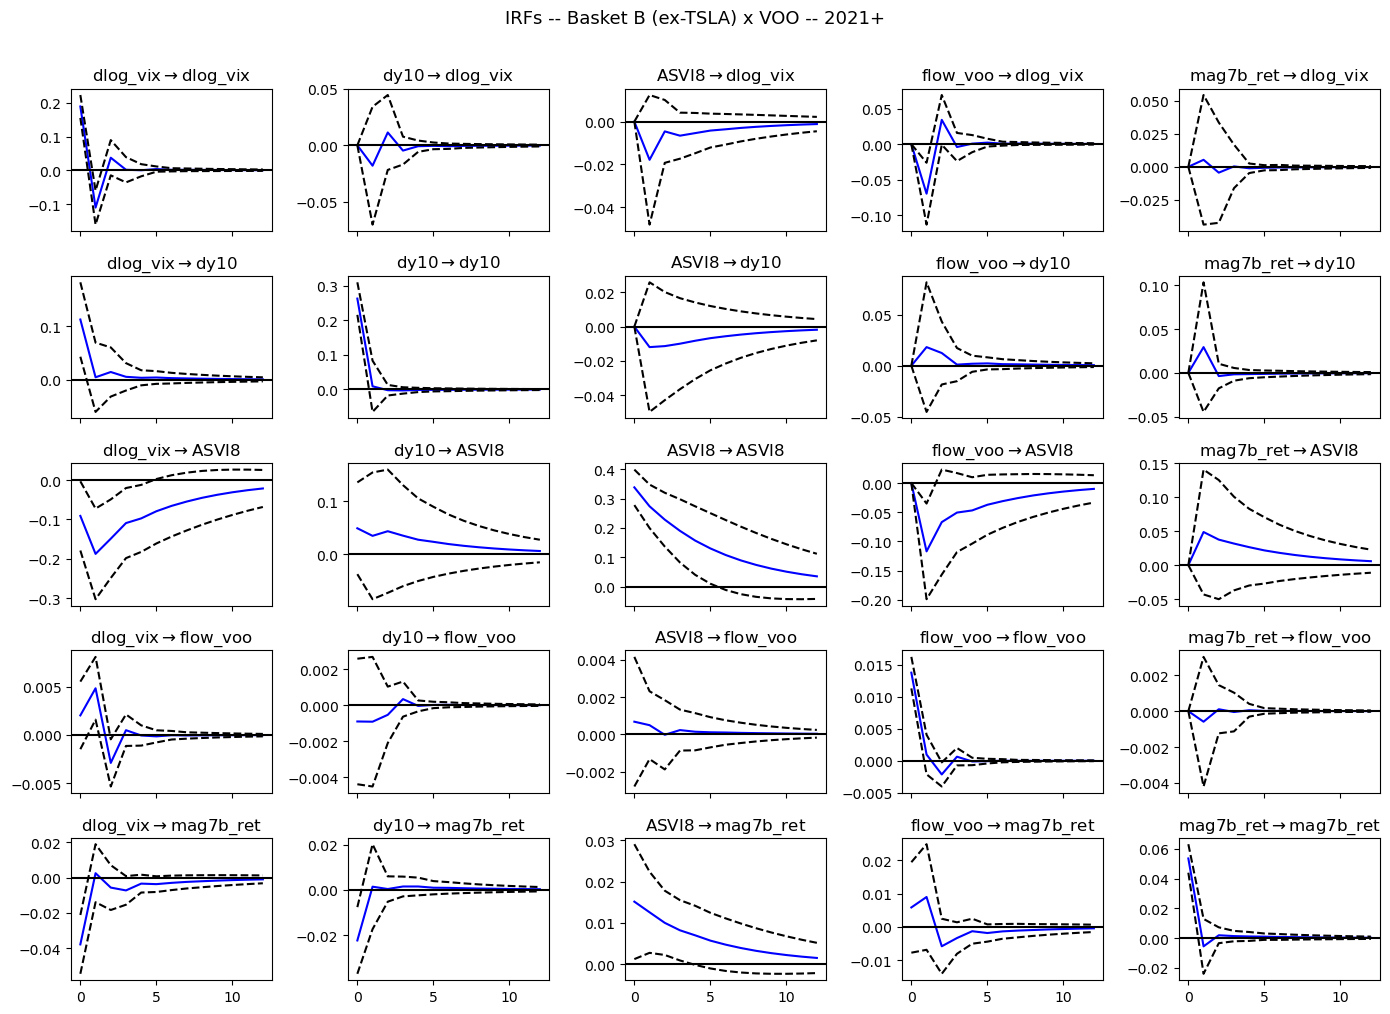

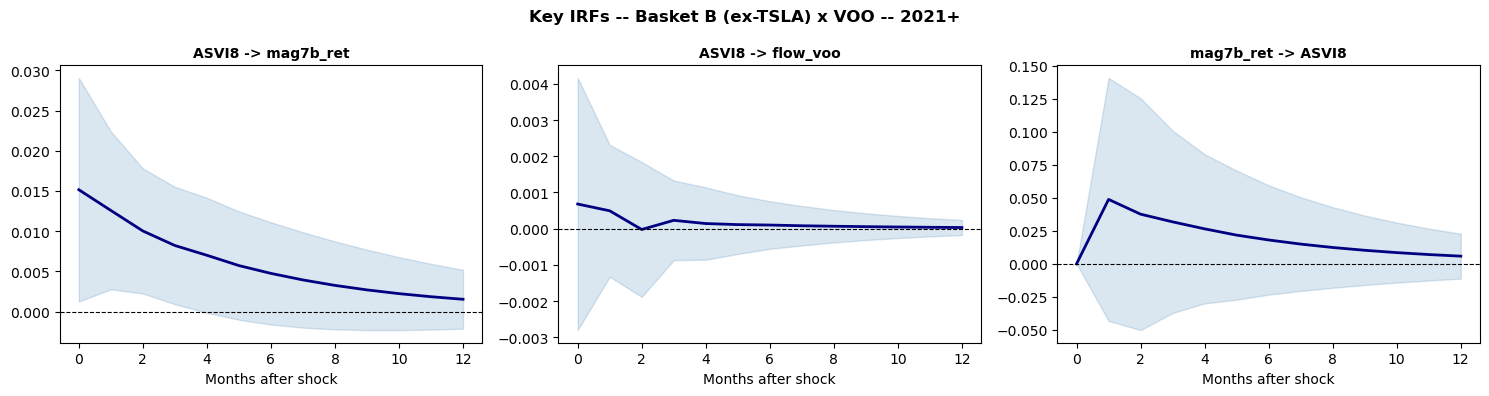

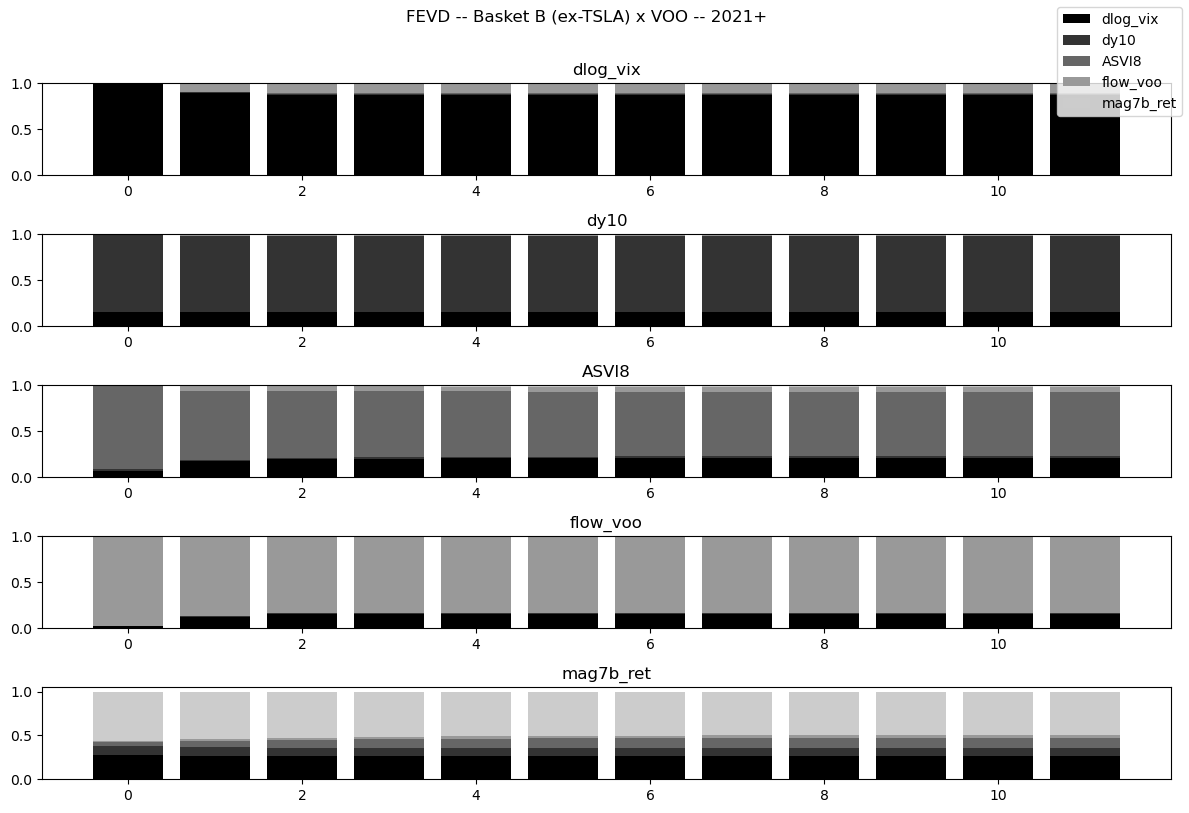


FEVD -- mag7b_ret:
Variable             t=1       t=6      t=12
--------------------------------------------
dlog_vix          28.3%    26.8%    26.8%
dy10               9.9%     8.8%     8.7%
ASVI8              4.5%    11.1%    12.0%
flow_voo           0.7%     2.9%     2.9%
mag7b_ret         56.6%    50.4%    49.6%


In [14]:
results_b_voo_21 = run_var_basket(
    var_name   = "Basket B (ex-TSLA) x VOO -- 2021+",
    flow_col   = "flow_voo",
    basket_col = "mag7b_ret",
    data       = var_df_2021,
)


  Basket C (AI-pure 4) x SPY -- 2021+  |  N=61
  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_spy', 'mag7c_ret']

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -19.55      -19.37   3.249e-09      -19.48
1     -20.63*     -19.55*  1.105e-09*     -20.21*
2      -20.54      -18.57   1.228e-09      -19.78
3      -20.30      -17.43   1.648e-09      -19.19
4      -20.48      -16.72   1.530e-09      -19.02
-------------------------------------------------
BIC -> 1  |  AIC -> 1  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:44:08
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -19.4993
Nobs:                     60.0000    HQIC:              

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


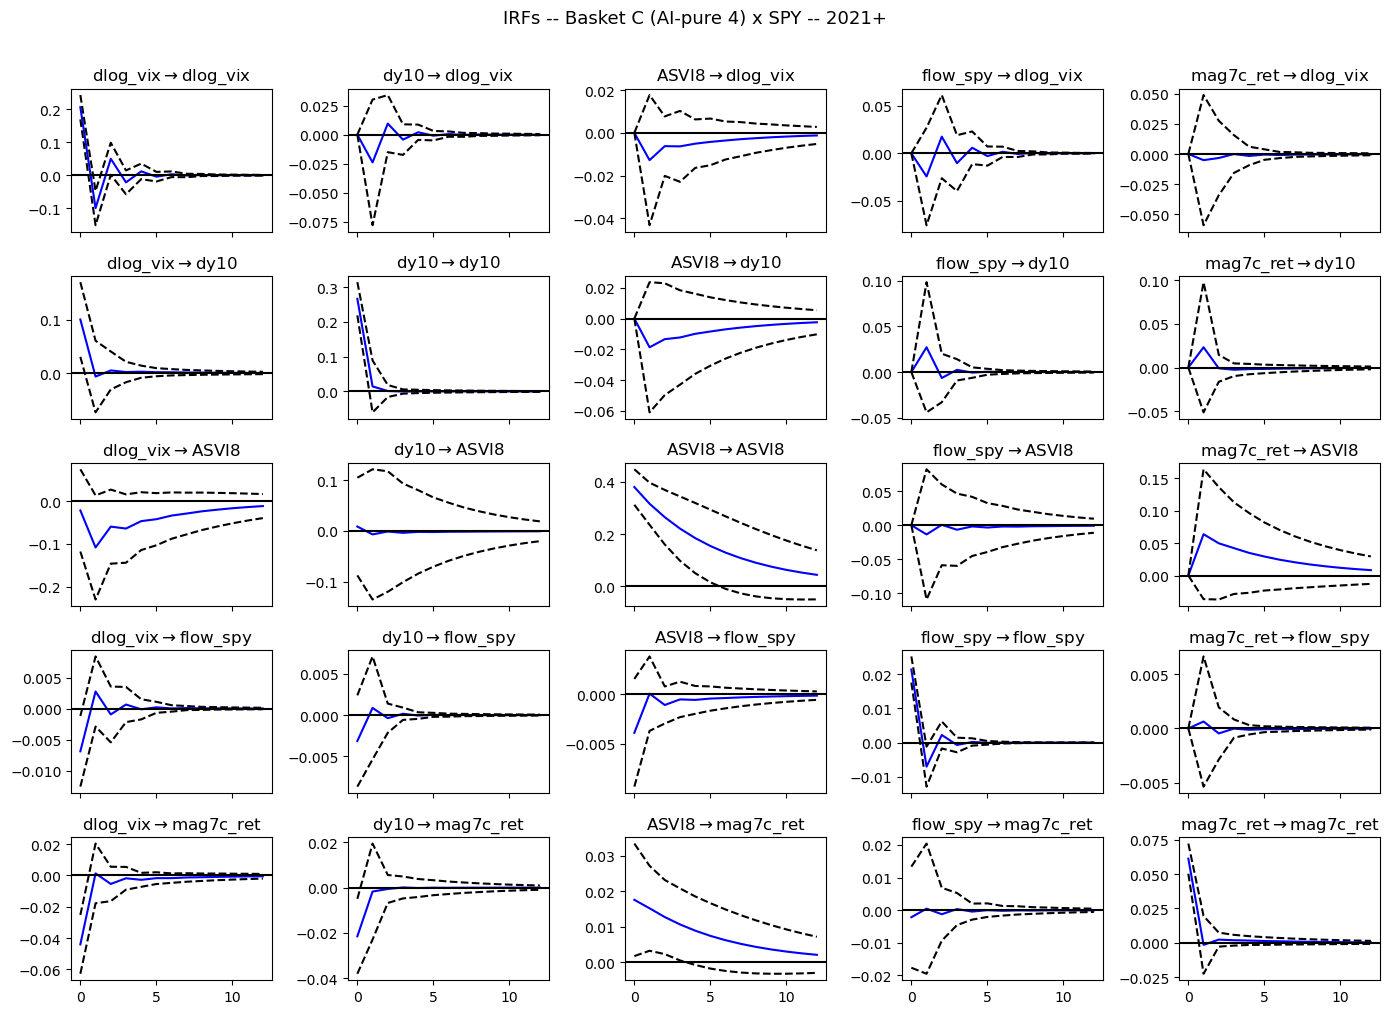

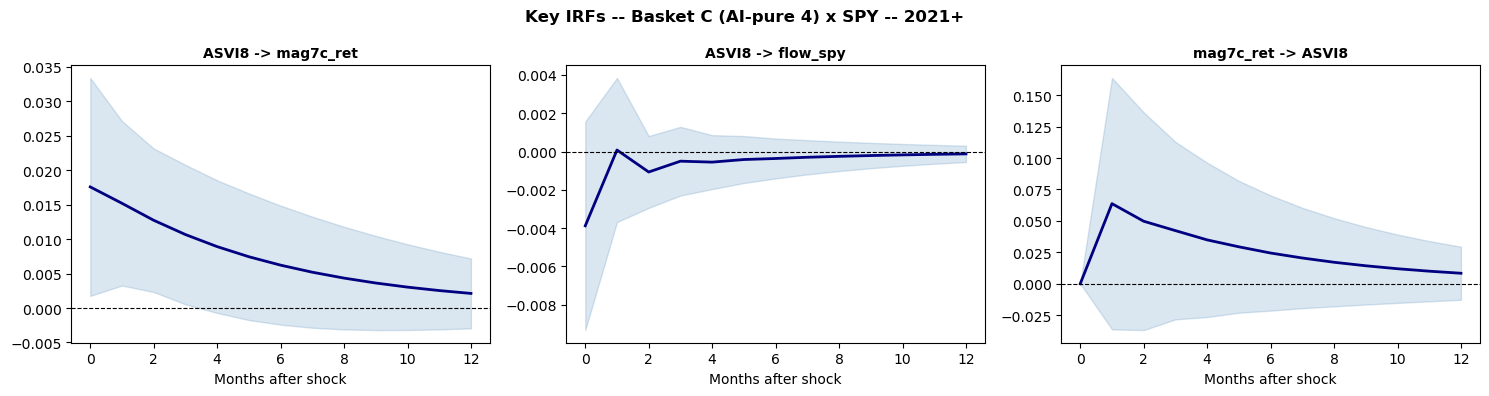

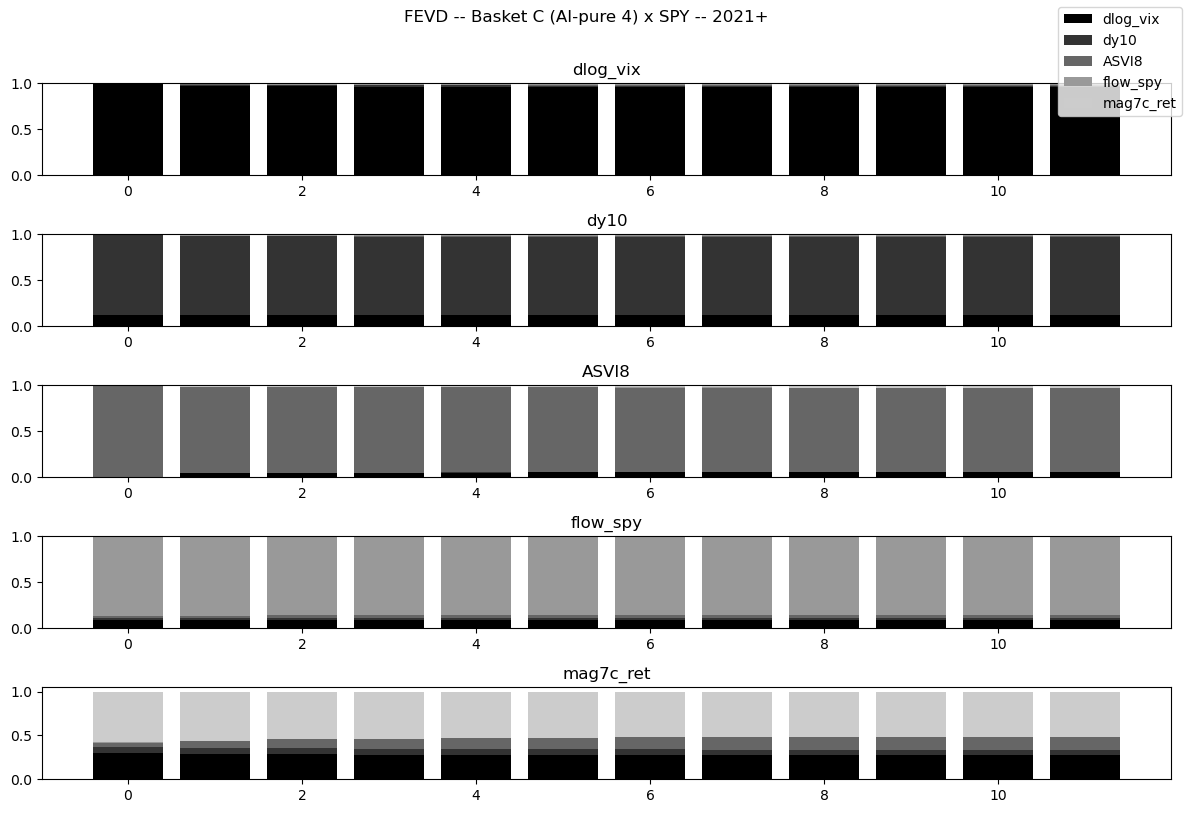


FEVD -- mag7c_ret:
Variable             t=1       t=6      t=12
--------------------------------------------
dlog_vix          30.0%    27.7%    27.3%
dy10               7.2%     6.5%     6.4%
ASVI8              4.8%    13.2%    14.6%
flow_spy           0.1%     0.1%     0.1%
mag7c_ret         57.9%    52.4%    51.6%


In [15]:
results_c_spy_21 = run_var_basket(
    var_name   = "Basket C (AI-pure 4) x SPY -- 2021+",
    flow_col   = "flow_spy",
    basket_col = "mag7c_ret",
    data       = var_df_2021,
)


  Basket C (AI-pure 4) x RSP -- 2021+  |  N=61
  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_rsp', 'mag7c_ret']

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -18.77      -18.59   7.032e-09      -18.70
1     -19.95*     -18.88*  2.171e-09*     -19.53*
2      -19.76      -17.79   2.685e-09      -18.99
3      -19.63      -16.76   3.229e-09      -18.51
4      -19.78      -16.02   3.083e-09      -18.32
-------------------------------------------------
BIC -> 1  |  AIC -> 1  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:44:09
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -18.6723
Nobs:                     60.0000    HQIC:              

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


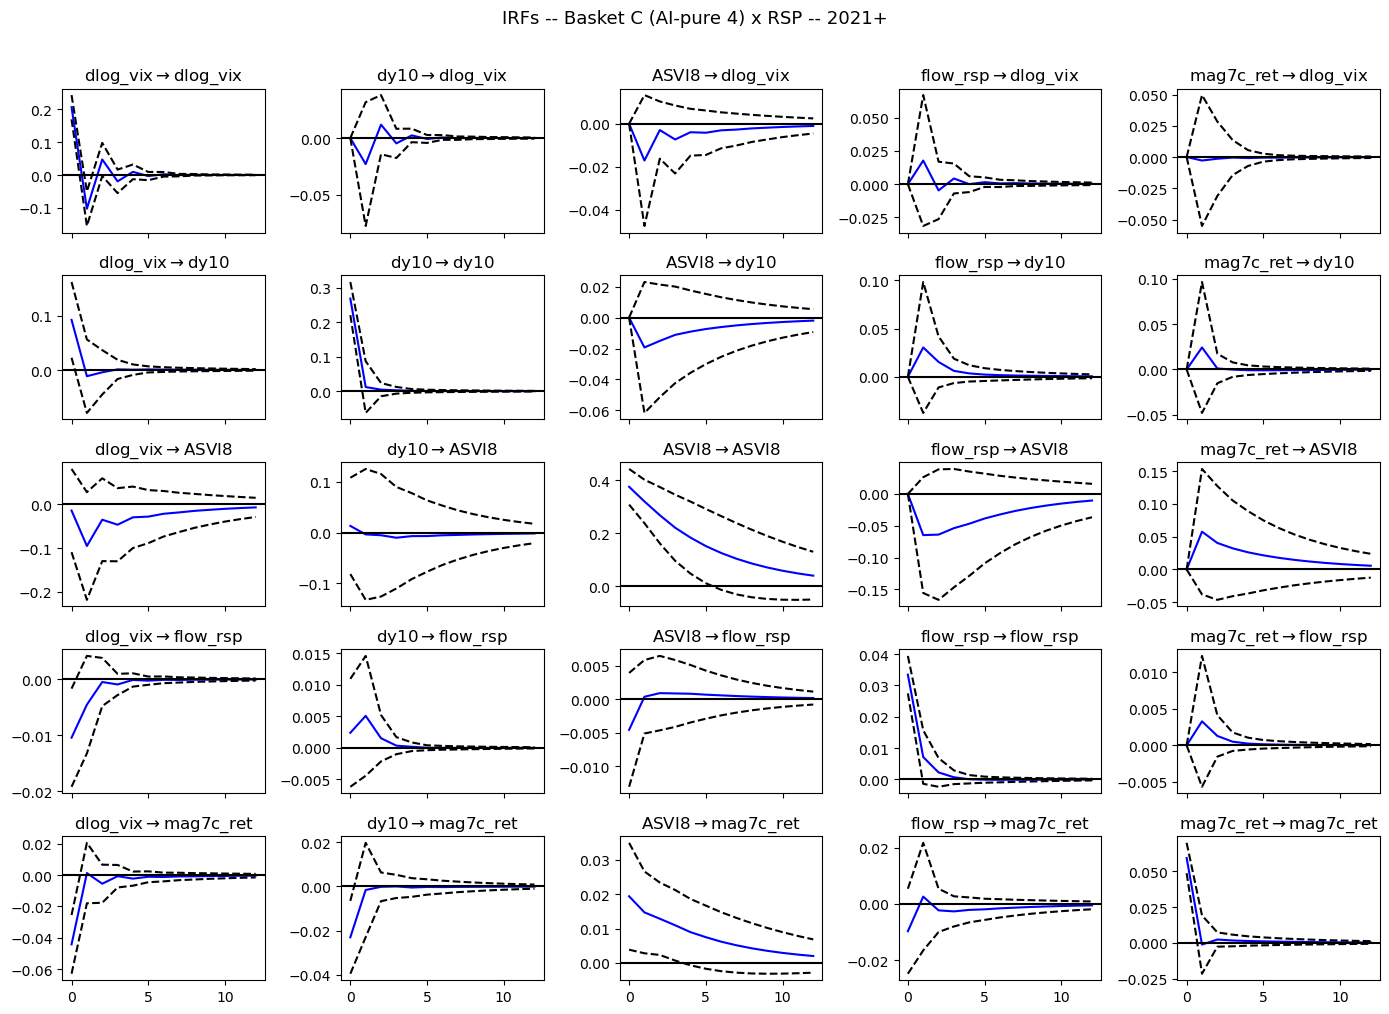

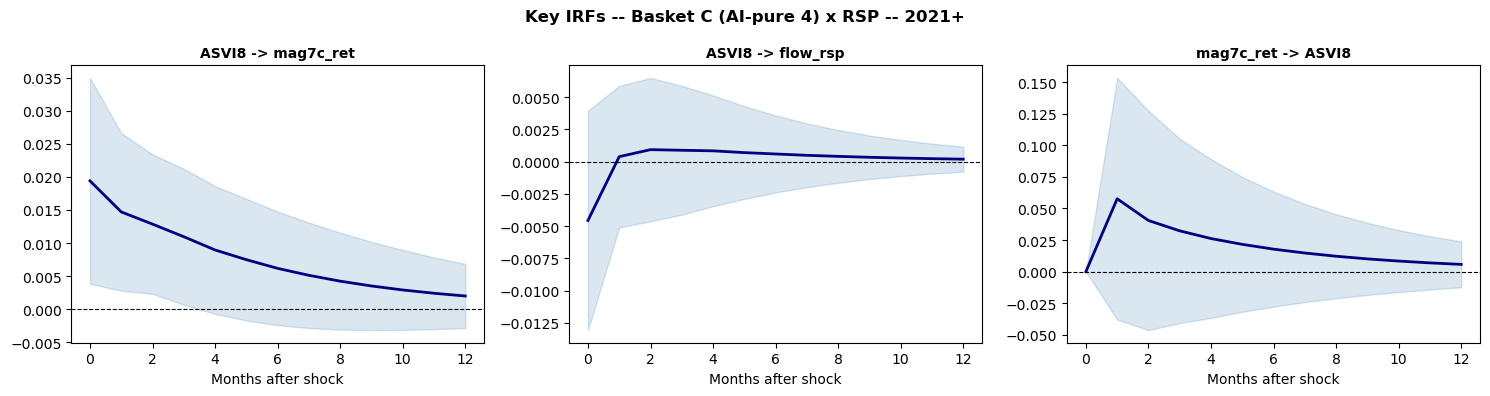

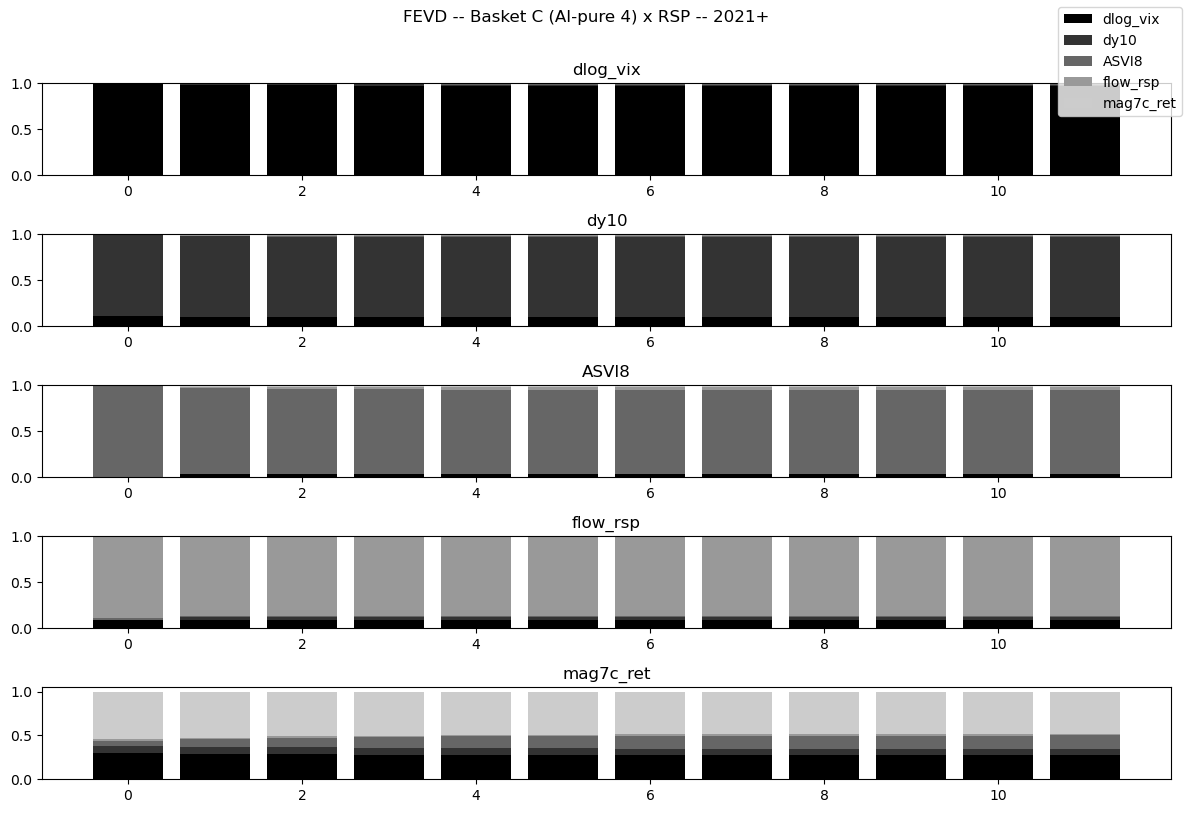


FEVD -- mag7c_ret:
Variable             t=1       t=6      t=12
--------------------------------------------
dlog_vix          30.3%    27.8%    27.4%
dy10               8.2%     7.4%     7.3%
ASVI8              5.8%    14.1%    15.4%
flow_rsp           1.5%     1.7%     1.8%
mag7c_ret         54.3%    49.0%    48.2%


In [16]:
results_c_rsp_21 = run_var_basket(
    var_name   = "Basket C (AI-pure 4) x RSP -- 2021+",
    flow_col   = "flow_rsp",
    basket_col = "mag7c_ret",
    data       = var_df_2021,
)


  Basket C (AI-pure 4) x VOO -- 2021+  |  N=61
  Variables: ['dlog_vix', 'dy10', 'ASVI8', 'flow_voo', 'mag7c_ret']

LAG SELECTION:
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -20.54      -20.36   1.196e-09      -20.47
1      -21.93     -20.85*   3.009e-10     -21.51*
2      -21.88      -19.90   3.238e-10      -21.11
3      -22.07      -19.21   2.798e-10      -20.96
4     -22.57*      -18.81  1.893e-10*      -21.11
-------------------------------------------------
BIC -> 1  |  AIC -> 4  |  Using: 1

VAR SUMMARY:
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sun, 04, Oct, 2026
Time:                     11:44:10
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -20.8397
Nobs:                     60.0000    HQIC:              

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


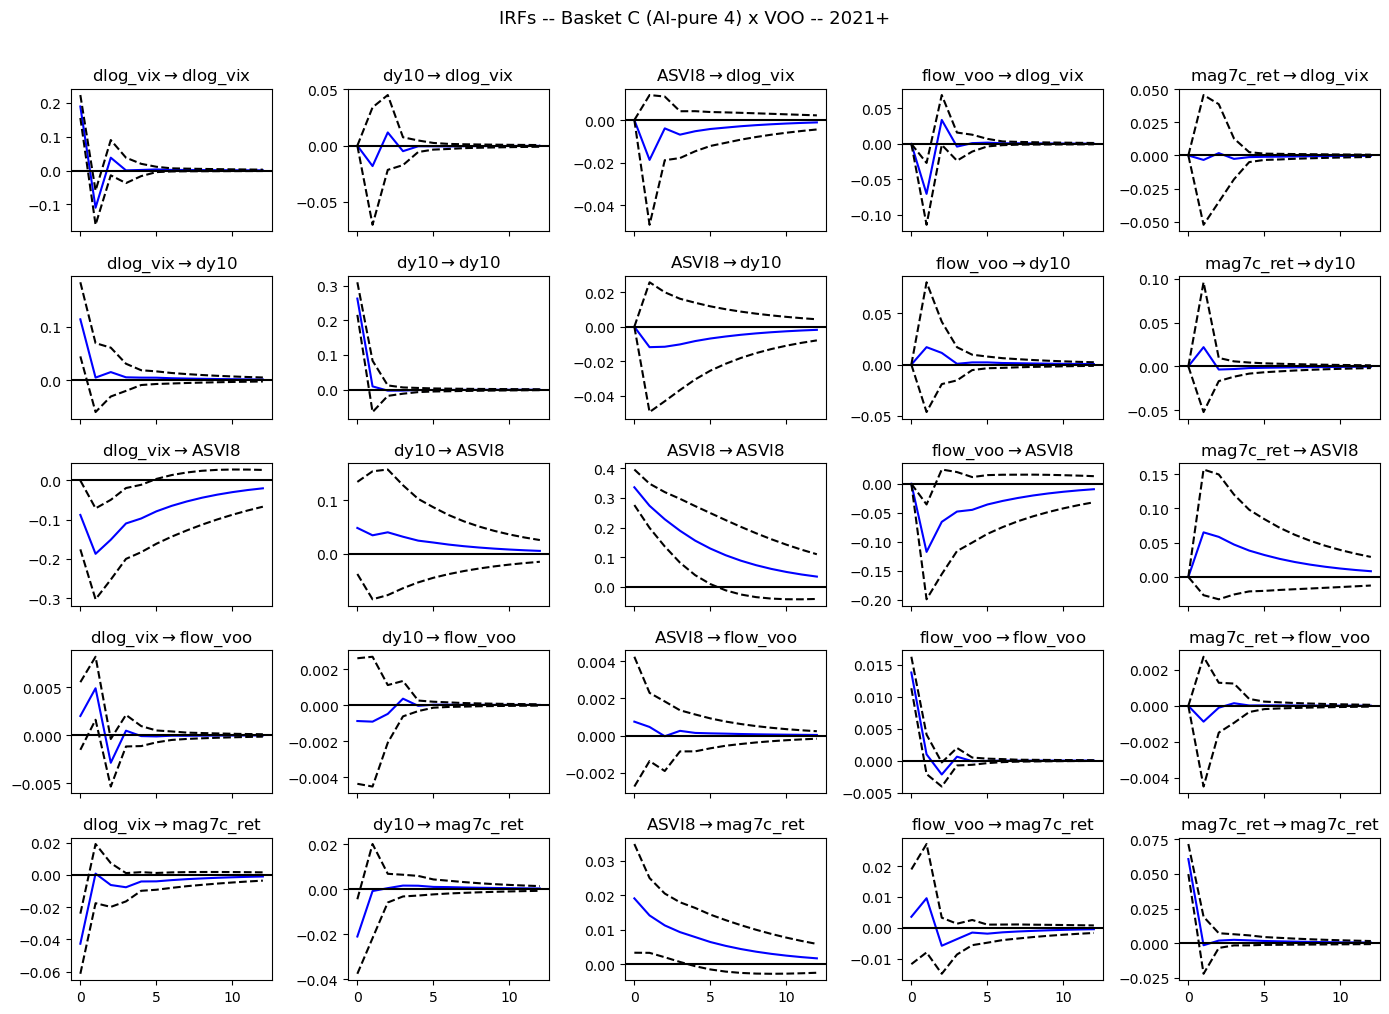

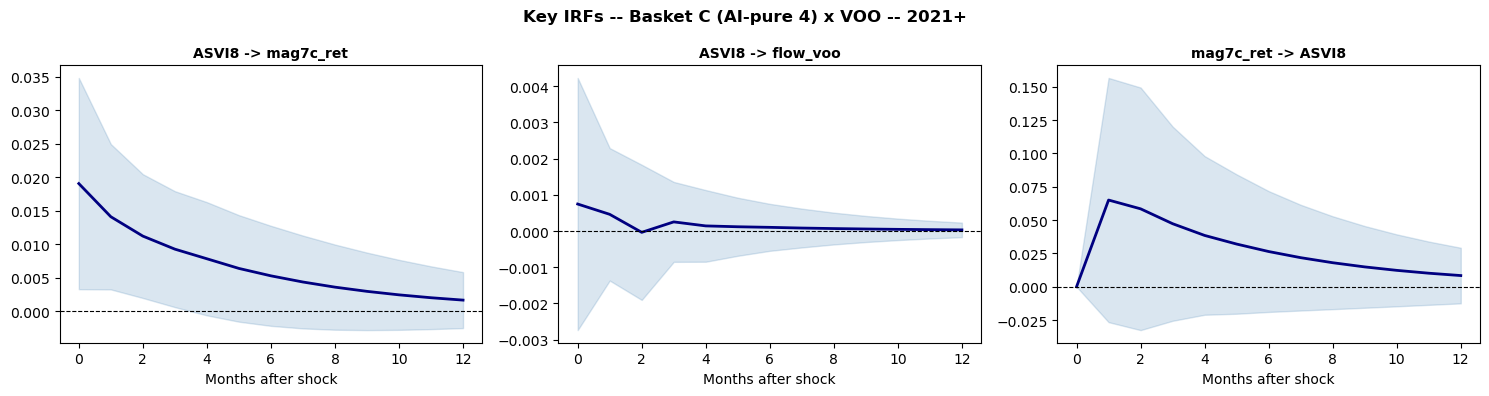

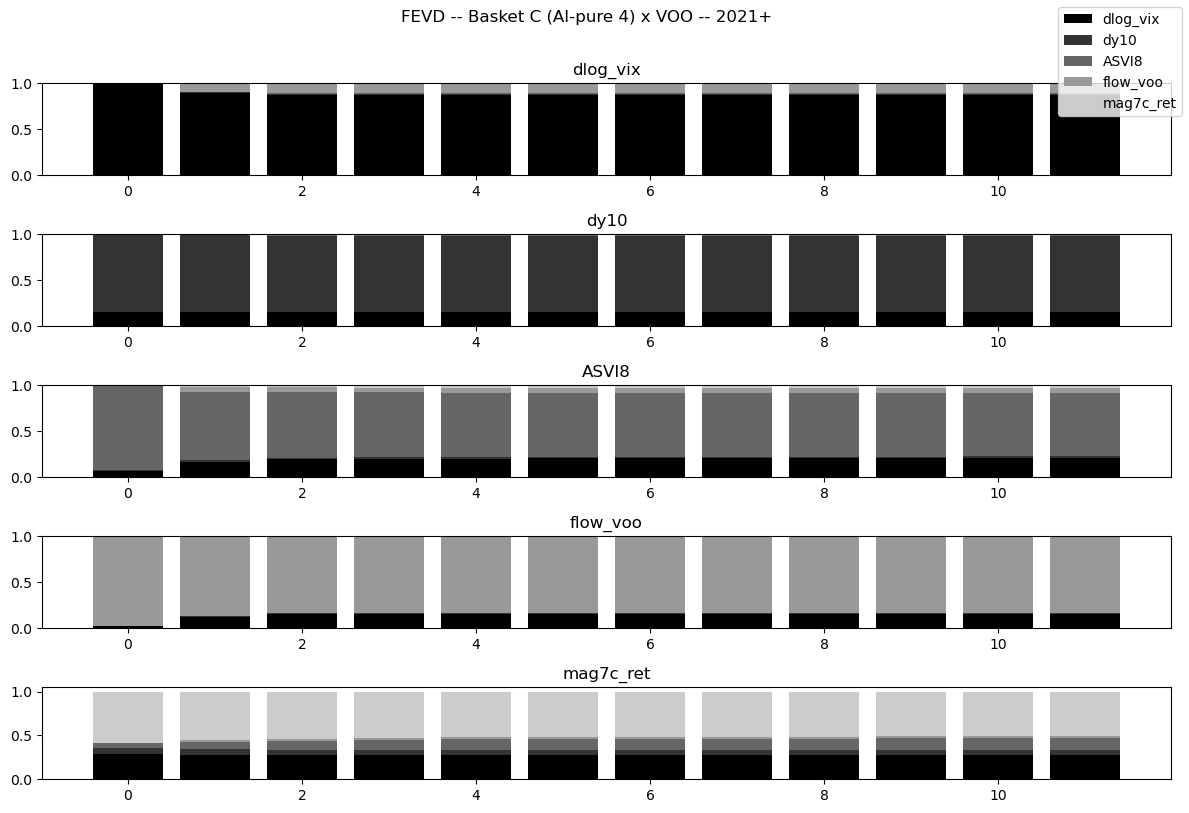


FEVD -- mag7c_ret:
Variable             t=1       t=6      t=12
--------------------------------------------
dlog_vix          28.8%    27.4%    27.3%
dy10               7.0%     6.3%     6.2%
ASVI8              5.7%    12.3%    13.2%
flow_voo           0.2%     2.2%     2.3%
mag7c_ret         58.2%    51.8%    51.0%


In [17]:
results_c_voo_21 = run_var_basket(
    var_name   = "Basket C (AI-pure 4) x VOO -- 2021+",
    flow_col   = "flow_voo",
    basket_col = "mag7c_ret",
    data       = var_df_2021,
)